# Powerset Validation Cache Benchmarks H100

**Thesis tested**: exact, differentiable attention over many subsets of a set becomes cheaper than off the shelf direct computation when the subsets are processed in an imposed canonical order (sorted, each prefix before its extensions) through a prefix tree, or trie. Shared prefix states are computed once in the forward pass, and shared subtree gradients are accumulated once in the backward pass.

**In plain terms**: a model that looks at many combinations of the same facts repeats work. The combinations {A, B, C} and {A, B, D} both begin with {A, B}. Sorting the combinations into one fixed order and storing them in a prefix tree lets every shared beginning be computed once and reused. The answer is unchanged; only the repeated work is removed.

**Purpose of this notebook**: on an RTX 2080 SUPER (8 GB), the cache was up to 2.08x faster than the fastest direct configuration in the attention only tier and up to 1.92x faster in a complete training step, with the advantage still growing at the largest budget the card could hold (M 112,000). This notebook asks two questions on an H100 (80 GB):

| Question | How it is answered |
|---|---|
| Does the speedup hold on current hardware, where the direct baselines run on faster kernels and far more memory bandwidth? | The same certified implementations, inputs, samplers and protocol, at the 2080's points |
| Does the speedup keep growing with the number of subsets? | M doubled from 64,000 to 512,000, 4.6x past the 2080's limit |

**Time budget**: under 5 hours of GPU time in total. H3 and H4 each carry a time guard (150 and 90 minutes) that skips, and lists, any point projected to exceed it. Points run smallest M first, so a guard can only remove the largest M points.

**Cells**

Cell numbers match the RTX 2080 SUPER notebook (H1 is V2C1, H3 is V2C3a, H4 is V2C4, H5 is V2C5), so results compare cell by cell. There is no H2. Its counterpart, V2C2, certifies sampler fairness and counts work sharing. Both are exact counts from the same seeded samplers, independent of the GPU, so they carry over unchanged.

| Cell | Content |
|---|---|
| Install | Pinned package versions, matching the 2080 run |
| Setup | Paths, uploaded file checks, launch mode check |
| H0 | Contract |
| H1 | Environment record and exactness certification on the H100 |
| H3 | Attention only tier, n 300 and 496, M 64,000 to 512,000 |
| H4 | Complete training step on real filings, at the points with a cache speedup |
| H5 | Figures and claims, H100 beside the 2080 |

**Files** (uploaded to `/workspace/pvcb`): the library (`set_attention.py`, `set_attention_cache.py`, `set_attention_model.py`, `set_attention_data.py`, `set_attention_bench.py`), the serialization module (`serialization.py`), the pretrained encoder (`set_encoder_tv_sem.pt`), the two filings with their concept name embeddings (`pvcb_h100_inputs.pkl.lz4`), and the RTX 2080 SUPER results (`pvcb_results_2080.pkl.lz4`). Results go to `pvcb_results_h100.pkl.lz4` in the same folder.

## Record for the paper

This notebook is standalone: every H100 number the paper uses is printed by a cell here and saved in `pvcb_results_h100.pkl.lz4`; the 2080 values it plots beside them are read from `pvcb_results_2080.pkl.lz4`, which is byte identical to the 2080 notebook's `pvcb_results_v2.pkl.lz4` (sha256 first 16: 0deaa0b8a4dc1adb).

| Paper claim | Cell | Key numbers |
|---|---|---|
| C1 exactness on the H100, same 16 workloads as the 2080 (identical subsets, nodes, facts and depths) | H1 | 1,024 comparisons, 0 failures; float64 outputs within 1.7e-14, gradients within 4.1e-13; float32 gradients within 1.1e-6 relative (tolerance 1e-3); the same SDPA kernels executed as on the 2080 (EFFICIENT_ATTENTION and MATH) |
| C1 exactness through a complete training step on real filings | H4 | every configuration that fit, timed or excluded, matched the reference; gradient relative difference at most 2.4e-6; float64 loss difference at most 1.1e-8 |
| C6 the speedup grows with M | H3 | every `powerset_runs` and `run_based` series rises at every doubling from 64,000 to 512,000; `powerset_runs` crosses parity between 64,000 and 128,000 at n 496 and between 128,000 and 256,000 at n 300; 2.26x at n 496, M 512,000 (L 10n) |
| C3 speed, attention only | H3 | `powerset_runs` 0.51x to 0.60x at M 64,000 and 1.38x to 2.26x at 512,000; `run_based` n 496 1.07x to 1.26x, n 300 0.69x to 0.74x; `uniform_powerset` 0.02x; the fastest direct configuration on the H100 is the unbatched `sdpa_masked` or `sdpa_masked_math` at every point |
| C3 speed, complete training step | H4 | `powerset_runs` 0.56x to 0.60x at M 64,000 and 1.29x to 1.94x at 512,000 (n 496, L 10n: 233.0 ms against 451.4 ms); `run_based` n 496 1.04x and 1.21x |
| Same point comparison, M 64,000 | H5 | the H100 runs the fastest direct configuration 4.6x to 6.2x faster than the 2080 and the cache 1.8x to 2.1x (`powerset_runs`, tries 174 to 280 levels deep) to 3.9x to 4.7x (shallower tries); a faster GPU raises the crossover and lifts the advantage past it |
| C2 memory | H3, H4 | not supported as written: above the lowest memory direct configuration at 28 of 28 H3 points; below the fastest direct configuration at 26 of 28 H3 points and at all 10 H4 points (about half at M 512,000) |

**Results files.** `pvcb_results_h100.pkl.lz4` (written by H1, H3, H4; read by H5) and `pvcb_results_2080.pkl.lz4` (read only). Inputs: `pvcb_h100_inputs.pkl.lz4` (sha256 first 16 2206e81ab1ead63c; filings 2019_QTR2_701347_0000701347-19-000022 with 300 facts and 2019_QTR2_763901_0001193125-19-144133 with 496 facts, selected by V2C4's rule, filings fingerprint 1d129ef73e6ce5e5, names 56f270b8e5f2c1b1, embeddings e110fb273dc306bf) and the pretrained encoder `set_encoder_tv_sem.pt` (f05614c86119d2bc).

**Environment (H1).** Python 3.12.3, numpy 1.26.4, pandas 2.2.2, torch 2.5.1+cu121, CUDA 12.1, cuDNN 90100, Linux 6.8.0; NVIDIA H100 80GB HBM3, 81,079 MiB, capability 9.0, one GPU; SDPA flash, memory efficient, math and cuDNN backends enabled; TF32 off for matmul and cuDNN (strict float32); launches asynchronous (0.24 ms issue against 42.46 ms GPU); seed 367. Library hashes identical to the 2080 run and checked in setup: `set_attention_cache` f53957e0033d0c72, `set_attention_model` 647b44ba68fe9dd4, `set_attention_data` 9ea47fe86942f3b6, `set_attention_bench` bb6728c9438c02d5. `serialization.py` on the pod was the standalone module written by export part 2 (5,429 bytes), which replaced the package stub listed in the export manifest (1,570 bytes).

**Measurement rules (H0).** As in the 2080 notebook: 2 untimed warmups then 5 timed repeats with the median reported and every repeat saved; peak memory reset between configurations; out of memory recorded, never retried; a direct configuration whose first warmup exceeds 10x the fastest median at the point is recorded as excluded and not timed (it cannot be the fastest); time guards of 150 min (H3) and 90 min (H4), with 0 points skipped; all 28 H3 points in 49.9 min and all 10 H4 points in 33.7 min.

## H0. Contract

### Claims

| ID | Claim | In plain terms | Measured in |
|---|---|---|---|
| C1 | Exactness: the cache produces the same outputs and gradients as direct computation on the H100 | The shortcut does not change the answer or the training signal on this hardware | H1, H4 |
| C2 | Memory: lower total peak GPU memory than direct computation | It needs less GPU memory | H3 |
| C3 | Time: faster than the fastest direct configuration | It finishes sooner than the best standard method | H3, H4 |
| C6 | Scaling: the speedup at fixed n grows with M | Processing more subsets widens the cache's lead | H3 |

Not claimed: any predictive benefit; results beyond the measured grid, hardware and implementations. Sharing counts (C4) and sampler fairness (C5) do not depend on hardware; they are certified in the RTX 2080 SUPER run and not repeated.

### Terms

| Term | Meaning |
|---|---|
| n | Number of facts in the set |
| T | Number of possible nonempty subsets, 2^n − 1 |
| M, P | Requested and actual number of subsets processed |
| Canonical order | One fixed sorted order of all subsets in which every subset comes right after its prefix |
| nodes / facts | Trie nodes divided by the total facts across all subsets: 1 means no sharing, lower means more sharing |
| speedup_vs_best | Fastest direct time / cache time; above 1 means the cache is faster |

### Hardware and software

| Item | Setting |
|---|---|
| GPU | NVIDIA H100 80 GB (model recorded in H1) |
| Software | torch 2.5.1 + CUDA 12.1, numpy 1.26.4, pandas 2.2.2: the RTX 2080 SUPER run's versions |
| Library | The 2080 run's library files, unchanged (source hashes checked in setup) |
| Precision | float32 with TF32 off, matching the 2080, which has no TF32 |
| Launches | Asynchronous, as in normal training; checked in setup and recorded |

### Methods compared

Inputs: one query q [C, d] and facts K, V [n, C, d], C = 24 channels, d = 80, drawn from a seeded standard normal (seed 367 + n).

| Method | What it does |
|---|---|
| `cache` | The invention: walks the trie once, extending each shared prefix by one fact, then walks it in reverse for gradients |
| `sdpa_masked` | PyTorch's standard attention (`scaled_dot_product_attention`) over all n facts, with a mask hiding facts outside each subset; default backend |
| `sdpa_masked_math` | The same call forced to PyTorch's reference math backend |
| `direct_gathered` | Copies each subset's facts out and runs attention on them separately |
| Chunking | Each direct method on all subsets at once and in batches of 4096, 1024 and 256 subsets |

13 configurations: `cache` plus 3 direct methods × 4 batch sizes. Every comparison is against the fastest direct configuration at that point.

### Samplers

Every sample is sorted into canonical order before processing.

| Sampler | Selection | In plain terms |
|---|---|---|
| `uniform_powerset` | Single subsets at a fixed stride across the canonical order, from a random start | Fair, but the chosen subsets rarely share prefixes |
| `run_based` | Runs of 8 neighboring subsets within sizes 4, 8, 16, 32 and 64 | Small groups of similar subsets of chosen sizes |
| `powerset_runs` | Evenly spaced starting points, each followed for L consecutive subsets; shifted by a random offset so every subset has inclusion probability exactly P / T. L = n or 10n | Fair, and each pick brings its neighbors, which share prefixes |

### Experiments

| Cell | Points | Purpose |
|---|---|---|
| H1 | The 2080's exactness suite: 16 workloads, all 13 configurations plus chunk sizes 64 and 7, float64 and float32, CPU and GPU | Certify exactness on the H100 before any timing |
| H3 | n {300, 496} × M {64,000, 128,000, 256,000, 512,000} × {`powerset_runs` L = n, `powerset_runs` L = 10n, `run_based`}; `uniform_powerset` at M 64,000 and 128,000 only | Speed and memory at the 2080's points and 4.6x beyond its memory limit |
| H4 | Every sampler and n with a cache speedup at some M in H3, at M 64,000 and at the largest M measured for it in H3 | Whether the speedup survives a complete training step, at a 2080 point and at the largest size |

Order: points run smallest M first, across all samplers and n.

Growth rule: for each sampler and n, M grows until the cache runs out of memory; larger M is not attempted after that. A point where every direct configuration runs out of memory but the cache fits is reported as direct infeasible, with the cache's measured cost.

Time guards: before each point, its time is projected from the same sampler and n at the previous M, scaled by the ratio of M. A point whose projection would take the cell past its budget (H3 150 minutes, H4 90 minutes, counting time already spent) is skipped and listed. Total GPU time stays under 5 hours.

### Complete training step (H4)

One full training update of a real model on a real financial filing.

| Item | Setting |
|---|---|
| Data | The two filings used on the 2080 (300 and 496 facts), uploaded with their concept name embeddings; every fact kept |
| Model | Pretrained set encoder (`SemanticMaskedSetEncoder`, training mode) and subset interaction head (`SubsetInteractionStack`, hidden 256) |
| Loss | Huber loss, 0.5 × full set + 0.5 × mean over subsets; target 0 (only time and memory are measured) |
| Update | Backward pass and one AdamW step (learning rate 1e-4 head, 1e-5 encoder, weight decay 0.01) |
| Fairness | Model, optimizer and random states restored before every step; every configuration must reproduce the reference loss and gradients before it is timed |

### Correctness tolerances

| Check | Passes when |
|---|---|
| float64 (H1) | Outputs and gradients differ by at most 1e-9 + 1e-9 × the largest reference value |
| float32 (H1) | Outputs within 1e-6 + 1e-4 × the largest reference value; gradient relative difference at most 1e-3 |
| Complete step gradients (H4) | Relative difference at most 1e-3 for all parameters, the encoder and the head; the same parameters receive gradients |
| Complete step loss (H4) | Within 1e-6 + 1e-4 × the reference, with both losses recomputed in float64 from each configuration's own predictions. A float32 loss summed over hundreds of thousands of subsets carries a summation error that depends on summation order (measured at up to 2.8e-5 in the library's float32 loss at 510,000 subsets, while predictions agreed to 1.2e-6), so the float32 difference is recorded but not tested |
| Timed repeats (H4) | Each timed step's float32 loss matches its configuration's untimed equivalence run within the loss tolerance plus twice that configuration's measured float32 summation error |

### Measurement rules

- Each configuration: 2 untimed warmups, then 5 timed repeats; the median is reported and every repeat is saved.
- GPU memory is cleared and peak statistics are reset between configurations. Memory is the total peak allocated.
- Out of memory is recorded as a result, never retried.
- Excluded as too slow: a direct configuration whose first warmup (H3) or equivalence run (H4) takes more than 10x the fastest median already measured at that point is recorded as excluded and not timed. It cannot be the fastest direct configuration, so no speedup changes. In H4 it is still checked for equivalence.
- Favorable and unfavorable points are both reported. Memory is compared against both the fastest and the lowest memory direct configuration.

### Output

One results file, `pvcb_results_h100.pkl.lz4`, beside the notebook. The RTX 2080 SUPER results (`pvcb_results_2080.pkl.lz4`) are read only by H5, for side by side comparison.

In [1]:
# Install: package versions pinned to the RTX 2080 SUPER run (torch 2.5.1 + CUDA 12.1, numpy 1.26.4, pandas 2.2.2),
# so differences come from the hardware, not the software. Restart the kernel after this cell.
%pip install --quiet "torch==2.5.1" --index-url https://download.pytorch.org/whl/cu121
%pip install --quiet "numpy==1.26.4" "pandas==2.2.2" scipy lz4 matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchaudio 2.8.0+cu128 requires torch==2.8.0, but you have torch 2.5.1+cu121 which is incompatible.
torchvision 0.23.0+cu128 requires torch==2.8.0, but you have torch 2.5.1+cu121 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.23.0+cu128 requires torch==2.8.0, but you have torch 2.5.1+cu121 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Setup. Run first after the kernel restart. Asynchronous CUDA launches (CUDA_LAUNCH_BLOCKING removed before torch
# loads, then checked); strict float32 (TF32 off, matching the RTX 2080 SUPER, which has no TF32); every uploaded file
# checked against the export checksums; the library's source hashes checked against the 2080 run's record;
# `apriori.serialization` resolved to the uploaded serialization.py so the certified cells run unchanged.

import os, sys, hashlib, inspect, platform, time
os.environ.pop("CUDA_LAUNCH_BLOCKING", None)
PVCB_DIR = "/workspace/pvcb"
if PVCB_DIR not in sys.path:
    sys.path.insert(0, PVCB_DIR)
os.chdir(PVCB_DIR)

# ----- uploaded files: sha256 (first 16 hex) from the export manifests -----
EXPECTED = {"pvcb_h100_inputs.pkl.lz4": "2206e81ab1ead63c", "pvcb_results_2080.pkl.lz4": "0deaa0b8a4dc1adb",
            "set_attention.py": "8580eb3ce583edec",
            "set_attention_bench.py": "80b9a7eddb88ddee", "set_attention_cache.py": "341de32d3617f1ee",
            "set_attention_data.py": "6c357cbf2a9f0896", "set_attention_model.py": "4dcf2217d75f826f",
            "set_encoder_tv_sem.pt": "f05614c86119d2bc"}
SERIALIZATION_BYTES = 5429                                 # serialization.py, from the export (part 2)

def sha16_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f_:
        for blk in iter(lambda: f_.read(1 << 20), b""):
            h.update(blk)
    return h.hexdigest()[:16]

def sha16(s):
    return hashlib.sha256(s.encode()).hexdigest()[:16]

bad = {f_: (sha16_file(f_) if os.path.isfile(f_) else "missing") for f_ in EXPECTED}
bad = {f_: v for f_, v in bad.items() if v != EXPECTED[f_]}
assert not bad, f"uploaded files differ from the export: {bad}"
assert os.path.isfile("serialization.py") and os.path.getsize("serialization.py") == SERIALIZATION_BYTES, \
    "serialization.py missing or not the exported submodule"

# ----- apriori.serialization -> the uploaded module (no other apriori code exists on this machine) -----
os.makedirs(os.path.join(PVCB_DIR, "apriori", "serialization"), exist_ok=True)
with open(os.path.join(PVCB_DIR, "apriori", "__init__.py"), "w") as f_:
    f_.write("")
with open(os.path.join(PVCB_DIR, "apriori", "serialization", "__init__.py"), "w") as f_:
    f_.write("from serialization import save_to_pickle, load_from_pickle\n")
from apriori.serialization import save_to_pickle, load_from_pickle

# ----- packages and GPU -----
import numpy as np
import pandas as pd
import torch
PINS = {"torch": "2.5.1+cu121", "numpy": "1.26.4", "pandas": "2.2.2"}
have = {"torch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__}
assert have == PINS, f"package versions differ from the pins: {have} (run the install cell, restart the kernel)"
assert torch.cuda.is_available(), "CUDA is required"
GPU = torch.cuda.get_device_properties(0)
assert "H100" in GPU.name, f"this notebook runs on an H100; found {GPU.name}"
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# ----- library: imports and source hashes equal the 2080 run's -----
import set_attention, set_attention_cache, set_attention_model, set_attention_data, set_attention_bench
LIB_MODS = (set_attention_cache, set_attention_model, set_attention_data, set_attention_bench)
lib_now = {m.__name__: sha16(inspect.getsource(m)) for m in LIB_MODS}
store_2080 = load_from_pickle("pvcb_results_2080.pkl.lz4")
assert lib_now == store_2080["env"]["library_sha16"], \
    f"library source differs from the 2080 run: {lib_now} vs {store_2080['env']['library_sha16']}"

# ----- launch mode: asynchronous launches required -----
_A = torch.randn(4096, 4096, device="cuda"); _B = torch.randn(4096, 4096, device="cuda"); _C = torch.empty_like(_A)
torch.mm(_A, _B, out=_C); torch.cuda.synchronize()
_e0, _e1 = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
_e0.record(); _t0 = time.perf_counter()
for _ in range(16):
    torch.mm(_A, _B, out=_C)
_issue = 1000 * (time.perf_counter() - _t0); _e1.record(); torch.cuda.synchronize()
_gpu = _e0.elapsed_time(_e1)
del _A, _B, _C; torch.cuda.empty_cache()
LAUNCH = {"cuda_launch_blocking": os.environ.get("CUDA_LAUNCH_BLOCKING"), "launch_check_issue_ms": round(_issue, 2),
          "launch_check_gpu_ms": round(_gpu, 2),
          "launch_mode": "asynchronous" if _issue < 0.1 * _gpu else "synchronous"}
assert LAUNCH["launch_mode"] == "asynchronous", f"CUDA launches are synchronous: {LAUNCH}"

RESULTS = os.path.join(PVCB_DIR, "pvcb_results_h100.pkl.lz4")
print("SETUP PASSED")
print(f"  gpu: {GPU.name}, {round(GPU.total_memory / 2**20):,} MiB, capability {GPU.major}.{GPU.minor}")
print(f"  python {platform.python_version()}; torch {torch.__version__}; numpy {np.__version__}; pandas {pd.__version__}")
print(f"  TF32: matmul {torch.backends.cuda.matmul.allow_tf32}, cudnn {torch.backends.cudnn.allow_tf32} (strict float32)")
print(f"  uploaded files: {len(EXPECTED)} match the export checksums; serialization.py {SERIALIZATION_BYTES:,} bytes")
print(f"  library_sha16 equal to the 2080 run: {lib_now}")
print(f"  launch check: 16 matrix multiplies, host issue {LAUNCH['launch_check_issue_ms']} ms vs GPU "
      f"{LAUNCH['launch_check_gpu_ms']} ms: {LAUNCH['launch_mode']}")
print(f"  results file: {RESULTS}")

SETUP PASSED
  gpu: NVIDIA H100 80GB HBM3, 81,079 MiB, capability 9.0
  python 3.12.3; torch 2.5.1+cu121; numpy 1.26.4; pandas 2.2.2
  TF32: matmul False, cudnn False (strict float32)
  uploaded files: 8 match the export checksums; serialization.py 5,429 bytes
  library_sha16 equal to the 2080 run: {'set_attention_cache': 'f53957e0033d0c72', 'set_attention_model': '647b44ba68fe9dd4', 'set_attention_data': '9ea47fe86942f3b6', 'set_attention_bench': 'bb6728c9438c02d5'}
  launch check: 16 matrix multiplies, host issue 0.24 ms vs GPU 42.46 ms: asynchronous
  results file: /workspace/pvcb/pvcb_results_h100.pkl.lz4


## H1. Environment record and exactness certification

Certifies claim C1 on the H100 before any timing, with the RTX 2080 SUPER suite unchanged. Every method and batch size is run on 16 test workloads covering all three samplers. Its outputs and its gradients for q, K and V are compared with a float64 reference (`sdpa_masked_math`, all subsets at once, same device). Tolerances are those in H0.

**In plain terms**: before anything is timed on the new GPU, every method must be shown to give the same answer and the same training signal as the reference, on the CPU and on the GPU, in double and single precision. A different GPU runs different kernels, so exactness is certified again rather than assumed. The cell stops unless every float64 configuration and every GPU float32 configuration passes, including all 13 benchmark configurations.

**Printed output, in order**

**H1: ENVIRONMENT**

| Label | Meaning |
|---|---|
| python, numpy, pandas, torch | Versions |
| cuda_runtime, cudnn | CUDA runtime and cuDNN versions |
| platform | Operating system |
| seed, key_tag | 367, "pvcb" |
| library_sha16 | Source hashes of the library files; equal to the 2080 run's (checked in setup) |
| gpu, gpu_memory_MiB, gpu_capability, gpu_count | The GPU |
| sdp_enabled_flags | Which PyTorch attention backends are enabled |
| tf32 | TF32 settings for matrix multiplies and cuDNN (both False: strict float32) |
| launch | The setup cell's launch check (asynchronous) |

**H1: CERTIFICATION WORKLOADS**

| Label | Meaning |
|---|---|
| case | Workload description |
| sampler | `uniform_powerset`, `run_based` or `powerset_runs` |
| run_len | Run length L (`powerset_runs` only; None otherwise) |
| set_sizes | Facts per set (several sets means mixed sizes, concatenated) |
| M | Subsets requested per set |
| subsets | Actual subsets P |
| trie_nodes | Prefix states the cache computes |
| subset_facts | Total facts across all subsets |
| depth | Trie levels |
| q_scale | Query scale (4 stresses the softmax) |
| repeated_facts | True if some fact appears at several trie nodes |
| internal_terminals | True if some subset ends at an internal trie node |
| single_fact_subsets | True if some subset has one fact |

**H1: EQUIVALENCE** (comparison count and minutes in the header)

| Label | Meaning |
|---|---|
| device, dtype, impl, chunk | The configuration |
| cases | Workloads compared |
| ok, fail, unsupported | Count by outcome |
| max_err_out | Largest absolute output difference |
| max_err_grad_q, max_err_grad_K, max_err_grad_V | float64: largest absolute gradient difference; float32: norm of difference / norm of reference |

**H1: SDPA BACKEND EXECUTED**: device, impl, executed_backend (the attention kernel PyTorch actually ran, as recorded by the profiler), cases. On the H100 the default backend may differ from the 2080's; this records which one ran.

**H1: CERTIFICATION BY CONFIGURATION**: rows device, dtype, impl; columns chunk. Each cell reads certified, FAILED, not certified (unsupported), or not chunked (`cache`).

**UNSUPPORTED** and **FAILURES**: printed only if any occurred, with the configuration and case.

**EARLIER MEASUREMENTS**: whether a previous run's results were found in the results file and kept, or removed because the environment or library changed.

**H1 CERTIFICATION PASSED**: comparisons within tolerance, failures (0), unsupported, required configurations certified, total certified configurations (including the 13 benchmark configurations), and the results file.

In [4]:
# H1. Environment record and exactness certification (claim C1) on the H100, before any timing. The RTX 2080 SUPER
# suite unchanged: inputs q [C, d], K [N, C, d], V [N, C, d] (C = 24, d = 80), drawn in float64 and cast; loss
# sum(W * out). Every implementation and chunk size is compared, on outputs and on gradients for q, K and V, against
# the float64 unchunked sdpa_masked_math reference on the same device, with the tolerances in H0. Values must be
# finite before comparison; unsupported implementations are recorded, never skipped. The SDPA kernel actually
# executed is recorded with the profiler. Chunk sizes: all, 4096, 1024, 256 (benchmark) plus 64 and 7; one case per
# sampler exceeds 4096 subsets. Gate: every float64 configuration (CPU, GPU) and every cuda float32 configuration
# must pass every case, including all 13 benchmark configurations; otherwise the cell stops.
# Requires the setup cell (PVCB_DIR, RESULTS, sha16, LAUNCH, LIB_MODS).

import os, gc, inspect, platform, time
import numpy as np
import pandas as pd
import torch
import set_attention_cache, set_attention_model, set_attention_data, set_attention_bench
import set_attention_bench as B
from apriori.serialization import save_to_pickle, load_from_pickle

_need = ("PVCB_DIR", "RESULTS", "sha16", "LAUNCH", "LIB_MODS")
_missing = [k for k in _need if k not in globals()]
assert not _missing, f"kernel is missing {_missing}: run the setup cell first"
assert not torch.backends.cuda.matmul.allow_tf32 and not torch.backends.cudnn.allow_tf32, "TF32 must be off"

C_CH, D_HEAD = 24, 80
CERT_CHUNKS = (4096, 1024, 256, 64, 7)
TOL64 = (1e-9, 1e-9)                      # absolute, relative to max abs reference
TOL32_OUT = (1e-6, 1e-4)
TOL32_GRAD, TOL32_ZERO = 1e-3, 1e-6
TOL64_ZERO = 1e-9
DEVICES = ["cpu", "cuda"]

# ----- environment record -----
pr = torch.cuda.get_device_properties(0)
env = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "torch": torch.__version__, "cuda_runtime": torch.version.cuda,
       "cudnn": torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else None,
       "platform": platform.platform(), "seed": B.SEED, "key_tag": B.KEY_TAG,
       "library_sha16": {m.__name__: sha16(inspect.getsource(m)) for m in LIB_MODS},
       "gpu": pr.name, "gpu_memory_MiB": round(pr.total_memory / 2**20), "gpu_capability": f"{pr.major}.{pr.minor}",
       "gpu_count": torch.cuda.device_count(),
       "sdp_enabled_flags": {"flash": torch.backends.cuda.flash_sdp_enabled(),
                             "mem_efficient": torch.backends.cuda.mem_efficient_sdp_enabled(),
                             "math": torch.backends.cuda.math_sdp_enabled(),
                             "cudnn": getattr(torch.backends.cuda, "cudnn_sdp_enabled", lambda: None)()},
       "tf32": {"matmul": torch.backends.cuda.matmul.allow_tf32, "cudnn": torch.backends.cudnn.allow_tf32},
       "launch": LAUNCH}

# ----- certification workloads (identical to the RTX 2080 SUPER run) -----
# (label, set sizes, M, sampler, query scale, run_len for powerset_runs)
CASES = [("all subsets of 5 facts (singletons, internal terminals, the full set)", [5], 31, "uniform_powerset", 1.0, None),
         ("12 facts, power set", [12], 300, "uniform_powerset", 1.0, None),
         ("12 facts, run based", [12], 300, "run_based", 1.0, None),
         ("12 facts, power set runs, L 12", [12], 300, "powerset_runs", 1.0, 12),
         ("mixed set sizes 3, 17, 40, power set", [3, 17, 40], 200, "uniform_powerset", 1.0, None),
         ("mixed set sizes 3, 17, 40, run based", [3, 17, 40], 200, "run_based", 1.0, None),
         ("mixed set sizes 3, 17, 40, power set runs, L 10 (3 facts: every subset)", [3, 17, 40], 200,
          "powerset_runs", 1.0, 10),
         ("64 facts, power set, query scale 4", [64], 500, "uniform_powerset", 4.0, None),
         ("64 facts, run based, query scale 4", [64], 500, "run_based", 4.0, None),
         ("64 facts, power set runs, L 64, query scale 4", [64], 500, "powerset_runs", 4.0, 64),
         ("105 facts, power set", [105], 2000, "uniform_powerset", 1.0, None),
         ("105 facts, run based", [105], 2000, "run_based", 1.0, None),
         ("105 facts, power set runs, L 105", [105], 2000, "powerset_runs", 1.0, 105),
         ("105 facts, power set, 5,000 subsets (splits at chunk 4096)", [105], 5000, "uniform_powerset", 1.0, None),
         ("105 facts, run based, 5,000 subsets (splits at chunk 4096)", [105], 5000, "run_based", 1.0, None),
         ("105 facts, power set runs, L 1050, 5,000 requested (4,200 actual; splits at chunk 4096)", [105], 5000,
          "powerset_runs", 1.0, 1050)]
workloads = []
for k, (label, ns, M, smp, qs, rl) in enumerate(CASES):
    wl = B.make_workload(ns, M, smp, tag=f"_cert{k}", run_len=rl)
    pos = [np.asarray(t["pos"]) for t in wl["tries"] if t is not None]
    term = [set(np.asarray(t["terminals"]).tolist()) & set(np.asarray(t["parent"]).tolist())
            for t in wl["tries"] if t is not None]
    wl.update({"label": label, "q_scale": qs, "seed": B.SEED + k,
               "repeated_facts": any(len(p_) > len(set(p_.tolist())) for p_ in pos),
               "internal_terminals": any(len(x) > 0 for x in term),
               "single_fact_subsets": any(len(S) == 1 for S in wl["subs"])})
    workloads.append(wl)
assert any(w["repeated_facts"] for w in workloads), "no workload with a fact at several trie nodes"
assert any(w["internal_terminals"] for w in workloads), "no workload with terminals at internal nodes"
assert any(w["single_fact_subsets"] for w in workloads), "no workload with single fact subsets"
assert any(len(w["ns"]) > 1 for w in workloads), "no mixed set size workload"
for _smp in ("uniform_powerset", "run_based", "powerset_runs"):
    assert any(w["P"] > max(CERT_CHUNKS) and w["sampler"] == _smp for w in workloads), \
        f"no {_smp} workload with more subsets than the largest chunk size ({max(CERT_CHUNKS)})"

def is_unsupported(e):
    msg = str(e).lower()
    return isinstance(e, (RuntimeError, NotImplementedError)) and any(
        s in msg for s in ("no available kernel", "not implemented", "not supported", "unsupported"))

def run_cfg(impl, chunk, wl, dtype, device):
    """(outputs, gq, gK, gV) as float64 CPU tensors, or the exception."""
    q, K, V = B.make_inputs(wl["N"], C_CH, D_HEAD, wl["seed"], dtype, device, wl["q_scale"])
    W = B.make_weights(wl["P"], C_CH, D_HEAD, wl["seed"], dtype, device)
    out = B.run_attention(impl, q, K, V, wl, W, chunk=chunk)
    res = [out.detach().double().cpu()] + [t.grad.detach().double().cpu() for t in (q, K, V)]
    del q, K, V, W, out
    return res

def compare(res, ref, dtype):
    """Per tensor errors and the pass flag under the contract's tolerances; finite guards first."""
    names = ("out", "grad_q", "grad_K", "grad_V")
    for nm, a in zip(names, res):
        if not bool(torch.isfinite(a).all()):
            return {"pass": False, "note": f"nonfinite {nm}"}
    row, ok = {}, True
    for nm, a, b in zip(names, res, ref):
        diff = a - b
        mad, mref = float(diff.abs().max()), float(b.abs().max())
        nd, nr = float(diff.norm()), float(b.norm())
        if not all(np.isfinite([mad, mref, nd, nr])):
            return {"pass": False, "note": f"nonfinite error or norm in {nm}"}
        if dtype == torch.float64:
            err = mad
            ok_t = mad <= TOL64[0] + TOL64[1] * mref
            if nm != "out" and nr == 0.0:
                ok_t = nd <= TOL64_ZERO
        elif nm == "out":
            err = mad
            ok_t = mad <= TOL32_OUT[0] + TOL32_OUT[1] * mref
        else:
            err = nd / nr if nr > 0 else nd
            ok_t = (nd / nr <= TOL32_GRAD) if nr > 0 else (nd <= TOL32_ZERO)
        row[f"err_{nm}"] = err
        ok = ok and ok_t
    row["pass"] = ok
    return row

rows1, backends = [], []
t0 = time.perf_counter()
for device in DEVICES:
    for wi, wl in enumerate(workloads):
        ref = run_cfg("sdpa_masked_math", None, wl, torch.float64, device)
        for t in ref:
            assert bool(torch.isfinite(t).all()), f"nonfinite float64 reference: {wl['label']} on {device}"
        cfgs = [(torch.float64, i, c) for i in ("cache", "sdpa_masked_math", "direct_gathered")
                for c in ([None] if i == "cache" else [None, *CERT_CHUNKS])]
        cfgs += [(torch.float32, i, c) for i in B.IMPLS
                 for c in ([None] if i == "cache" else [None, *CERT_CHUNKS])]
        for dtype, impl, chunk in cfgs:
            base = {"device": device, "dtype": str(dtype).replace("torch.", ""), "case": wl["label"],
                    "sampler": wl["sampler"], "P": wl["P"], "impl": impl,
                    "chunk": "all" if chunk is None else chunk}
            try:
                r = compare(run_cfg(impl, chunk, wl, dtype, device), ref, dtype)
                rows1.append({**base, "status": "ok" if r.get("pass") else "FAIL", **r})
            except Exception as e:
                if is_unsupported(e):
                    rows1.append({**base, "status": "unsupported", "pass": None,
                                  "note": f"{type(e).__name__}: {str(e)[:120]}"})
                else:
                    raise
        q, K, V = B.make_inputs(wl["N"], C_CH, D_HEAD, wl["seed"], torch.float32, device, wl["q_scale"])
        m_all = B.subset_mask(wl["subs"], wl["N"], device)
        for impl in ("sdpa_masked", "sdpa_masked_math"):
            try:
                ex = B.sdpa_executed_backend(q, K, V, m_all, impl == "sdpa_masked_math")
            except Exception as e:
                if not is_unsupported(e):
                    raise
                ex = f"unsupported ({type(e).__name__})"
            backends.append({"device": device, "case": wl["label"], "dtype": "float32", "impl": impl,
                             "executed_backend": ex})
        del q, K, V, m_all
        del ref
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()
mins1 = (time.perf_counter() - t0) / 60

eq = pd.DataFrame(rows1)
bk = pd.DataFrame(backends)
n_fail = int((eq["status"] == "FAIL").sum())
n_uns = int((eq["status"] == "unsupported").sum())
cfg_keys = ["device", "dtype", "impl", "chunk"]
cfg_status = (eq.groupby(cfg_keys, sort=False)["status"]
                .agg(lambda s: "certified" if (s == "ok").all() else
                     ("FAILED" if (s == "FAIL").any() else "not certified (unsupported)"))
                .rename("certification").reset_index())
required = cfg_status[(cfg_status["dtype"] == "float64") |
                      ((cfg_status["device"] == "cuda") & (cfg_status["dtype"] == "float32"))]
missing_req = required[required["certification"] != "certified"]
certified = [tuple(r) for r in cfg_status[cfg_status["certification"] == "certified"][cfg_keys].itertuples(index=False)]
BENCH_CONFIGS = [("cuda", "float32", "cache", "all")] + [("cuda", "float32", i, c)
                 for i in ("sdpa_masked", "sdpa_masked_math", "direct_gathered") for c in ("all", 4096, 1024, 256)]
missing_bench = [c for c in BENCH_CONFIGS if c not in set(certified)]

print("H1: ENVIRONMENT")
for k, v in env.items():
    print(f"  {k}: {v}")
print(f"\nH1: CERTIFICATION WORKLOADS (C = {C_CH}, d = {D_HEAD}):")
print(pd.DataFrame([{"case": w["label"], "sampler": w["sampler"], "run_len": w["run_len"], "set_sizes": w["ns"],
                     "M": w["M"],
                     "subsets": w["P"], "trie_nodes": w["nodes"], "subset_facts": w["facts"],
                     "depth": w["depth"], "q_scale": w["q_scale"], "repeated_facts": w["repeated_facts"],
                     "internal_terminals": w["internal_terminals"],
                     "single_fact_subsets": w["single_fact_subsets"]} for w in workloads]).to_string(index=False))
print(f"\nH1: EQUIVALENCE vs the float64 unchunked sdpa_masked_math reference on the same device "
      f"({len(eq)} comparisons, {mins1:.1f} min): summary by device, precision, implementation, chunk")
summ = (eq.assign(ok=eq["status"] == "ok", fail=eq["status"] == "FAIL", uns=eq["status"] == "unsupported")
          .groupby(["device", "dtype", "impl", "chunk"], sort=False)
          .agg(cases=("case", "size"), ok=("ok", "sum"), fail=("fail", "sum"), unsupported=("uns", "sum"),
               max_err_out=("err_out", "max"), max_err_grad_q=("err_grad_q", "max"),
               max_err_grad_K=("err_grad_K", "max"), max_err_grad_V=("err_grad_V", "max"))
          .reset_index())
print(summ.to_string(index=False))
print("\nH1: SDPA BACKEND EXECUTED (profiler, float32, gradient enabled, per case):")
print(bk.groupby(["device", "impl", "executed_backend"]).size().rename("cases").reset_index().to_string(index=False))
print("\nH1: CERTIFICATION BY CONFIGURATION (certified = every case passed):")
print(cfg_status.pivot_table(index=["device", "dtype", "impl"], columns="chunk", values="certification",
                             aggfunc="first").fillna("not chunked").to_string())
if n_uns:
    print("\nUNSUPPORTED (recorded, not skipped):")
    print(eq[eq["status"] == "unsupported"][["device", "dtype", "impl", "chunk", "case", "note"]].to_string(index=False))
if n_fail:
    print("\nFAILURES:")
    print(eq[eq["status"] == "FAIL"].to_string(index=False))

CERT_KEYS = {"env", "equivalence", "sdpa_executed_backend_cert", "certification", "certified_configs",
             "cert_workloads"}
store = load_from_pickle(RESULTS) if os.path.exists(RESULTS) else {}
old_env = store.get("env")
same_env = old_env is not None and all(old_env.get(k) == env.get(k) for k in
                                       ("library_sha16", "torch", "cuda_runtime", "cudnn", "gpu", "platform"))
stale = [k for k in store if k not in CERT_KEYS] if not same_env else []
for k in stale:
    del store[k]
store.update({"env": env, "equivalence": eq, "sdpa_executed_backend_cert": bk,
              "certification": cfg_status, "certified_configs": certified,
              "cert_workloads": [{k: w[k] for k in ("label", "ns", "M", "sampler", "run_len", "P", "nodes", "facts",
                                                     "depth", "q_scale", "seed")} for w in workloads]})
save_to_pickle(store, RESULTS, lz4_compression=True)
assert n_fail == 0, f"H1 CERTIFICATION FAILED: {n_fail} comparisons out of tolerance (see FAILURES)"
assert not missing_bench, f"H1 CERTIFICATION FAILED: benchmark configurations not certified: {missing_bench}"
assert missing_req.empty, ("H1 CERTIFICATION FAILED: required configurations not certified:\n"
                           + missing_req.to_string(index=False))
print(f"\nEARLIER MEASUREMENTS: {'none saved' if not old_env else ('kept (same environment and library source)' if same_env else 'INVALIDATED and removed: ' + (', '.join(stale) if stale else 'none present'))}")
print(f"\nH1 CERTIFICATION PASSED: {int((eq['status'] == 'ok').sum())} comparisons within tolerance, "
      f"0 failures, {n_uns} unsupported (recorded); every required configuration certified "
      f"({len(required)}: all float64 on CPU and GPU, all float32 on GPU); {len(certified)} certified "
      f"configurations saved, including all 13 benchmark configurations on cuda float32; every output, gradient, "
      f"error and norm finite; saved to {RESULTS}")

H1: ENVIRONMENT
  python: 3.12.3
  numpy: 1.26.4
  pandas: 2.2.2
  torch: 2.5.1+cu121
  cuda_runtime: 12.1
  cudnn: 90100
  platform: Linux-6.8.0-90-generic-x86_64-with-glibc2.39
  seed: 367
  key_tag: pvcb
  library_sha16: {'set_attention_cache': 'f53957e0033d0c72', 'set_attention_model': '647b44ba68fe9dd4', 'set_attention_data': '9ea47fe86942f3b6', 'set_attention_bench': 'bb6728c9438c02d5'}
  gpu: NVIDIA H100 80GB HBM3
  gpu_memory_MiB: 81079
  gpu_capability: 9.0
  gpu_count: 1
  sdp_enabled_flags: {'flash': True, 'mem_efficient': True, 'math': True, 'cudnn': True}
  tf32: {'matmul': False, 'cudnn': False}
  launch: {'cuda_launch_blocking': None, 'launch_check_issue_ms': 0.24, 'launch_check_gpu_ms': 42.46, 'launch_mode': 'asynchronous'}

H1: CERTIFICATION WORKLOADS (C = 24, d = 80):
                                                                                   case          sampler  run_len   set_sizes    M  subsets  trie_nodes  subset_facts  depth  q_scale  repeated_facts  inte

## H1 findings

**H1: ENVIRONMENT**

| Label | Value |
|---|---|
| python, numpy, pandas, torch | 3.12.3, 1.26.4, 2.2.2, 2.5.1+cu121 |
| cuda_runtime, cudnn | 12.1, 90100 |
| platform | Linux-6.8.0-90-generic-x86_64-with-glibc2.39 |
| seed, key_tag | 367, pvcb |
| library_sha16 | set_attention_cache f53957e0033d0c72; set_attention_model 647b44ba68fe9dd4; set_attention_data 9ea47fe86942f3b6; set_attention_bench bb6728c9438c02d5 (identical to the RTX 2080 SUPER run) |
| gpu, gpu_memory_MiB, gpu_capability, gpu_count | NVIDIA H100 80GB HBM3, 81,079, 9.0, 1 |
| sdp_enabled_flags | flash, mem_efficient, math and cudnn all enabled |
| tf32 | matmul False, cudnn False: strict float32 |
| launch | 16 matrix multiplies issued in 0.24 ms against 42.46 ms of GPU time: asynchronous |

**H1: CERTIFICATION WORKLOADS**: the 16 cases of the 2080 run, with identical actual subsets, trie nodes, facts and depths in every row. The samplers and the trie are deterministic, so the H100 certifies exactly the same workloads.

**H1: EQUIVALENCE** (1,024 comparisons, 11.5 min): every row 16 of 16 ok, 0 fail, 0 unsupported.

| Precision | Largest error, all implementations and chunk sizes | Tolerance |
|---|---|---|
| float64 (CPU, GPU) | outputs 1.7e-14; gradients 4.1e-13 (largest absolute difference) | 1e-9 + 1e-9 × largest reference value |
| float32 (CPU, GPU) | outputs 4.2e-6 (largest absolute difference); gradients 1.1e-6 (relative) | outputs 1e-6 + 1e-4 × largest reference value; gradients 1e-3 |

- `cache` matches the reference on both devices and in both precisions. float64: outputs within 1.7e-14, gradients within 4.1e-13. float32 on the GPU: outputs within 2.3e-6, gradients within 8.5e-7, essentially the 2080's values (2.3e-6 and 8.4e-7).
- Every batched direct configuration matches its unbatched form at every chunk size down to 7, for all three samplers.
- In plain terms: on the H100 the cache gives the same answer and training signal as standard attention to within rounding. float32 gradient errors are about 900x below the tolerance.

**H1: SDPA BACKEND EXECUTED**: on the GPU, `sdpa_masked` runs EFFICIENT_ATTENTION and `sdpa_masked_math` runs MATH in all 16 cases, the same kernels as on the 2080, so the direct baselines are like for like on faster hardware. On the CPU: FLASH_ATTENTION (cpu) and MATH.

**H1: CERTIFICATION BY CONFIGURATION**: every configuration is certified on both devices and in both precisions; `cache` is not chunked by design.

**EARLIER MEASUREMENTS**: none saved (first run on this machine).

**H1 CERTIFICATION PASSED**: 1,024 comparisons within tolerance, 0 failures, 0 unsupported. All 45 required configurations are certified (26 float64 across CPU and GPU, 19 cuda float32). 64 certified configurations are saved, including all 13 benchmark configurations on cuda float32. Claim C1 holds on the H100, and timing may proceed.

## H3. Speed and memory at larger M

Repeats the RTX 2080 SUPER's attention only comparison on the H100 and extends it 4.6x past the 2080's memory limit. Answers claims C3 (time), C2 (memory) and C6 (does the speedup grow with M?).

**In plain terms**: for each sample, the cache and the 12 direct configurations run the same attention forward and backward pass. Each is timed 5 times after 2 warmups, and its peak GPU memory is recorded. The number of subsets doubles from 64,000 to 512,000. The first point of each sampler and n repeats a 2080 point directly. `uniform_powerset`, which shares almost nothing, runs only at the two smallest sizes as a negative control.

**Points**: n {300, 496} × M {64,000, 128,000, 256,000, 512,000} × {`powerset_runs` L = n, `powerset_runs` L = 10n, `run_based`}, plus `uniform_powerset` at M 64,000 and 128,000: up to 28 workloads, 13 configurations each, smallest M first.

**Rules**
- Growth: once the cache runs out of memory for a sampler and n, larger M is skipped and listed.
- Time guard: before each point, its time is projected from the same sampler and n at the previous M, scaled by the ratio of M. A point that would take H3 past 150 minutes is skipped and listed.
- Exclusion: a direct configuration whose first warmup takes more than 10x the fastest median already measured at the point is recorded as excluded and not timed; it cannot be the fastest, so no speedup changes.
- The cell saves after every point and resumes where it stopped, counting time already spent against the budget.

**Printed output, in order**

Progress line while running: point number, sampler, n, M, minutes of the budget spent.

Header: GPU, precision, repeats, configurations per point, points measured and skipped, budget used, then the column definitions.

| Label | Meaning |
|---|---|
| sampler | `uniform_powerset`, `run_based` or `powerset_runs` |
| run_len | Run length L (`powerset_runs` only) |
| n | Facts in the set |
| M | Requested subsets |
| P | Actual subsets |
| nodes_over_facts | Trie nodes / total facts: lower means more sharing |
| depth | Trie levels |
| cache_status | ok, or oom |
| cache_ms | Cache median forward and backward time |
| cache_med_over_min | Cache median / minimum of the 5 repeats; near 1 means stable timing |
| cache_total_MiB | Cache total peak GPU memory |
| best_direct | Fastest direct configuration (method@batch size), or direct infeasible when none fit |
| best_direct_ms | Its median time |
| best_direct_med_over_min | Its median / minimum |
| best_direct_total_MiB | Its total peak GPU memory |
| speedup_vs_best | best_direct_ms / cache_ms; above 1 means the cache is faster |
| speedup_by_min | The same ratio on minimum times |
| lowest_total_direct | Direct configuration with the smallest peak memory |
| lowest_total_direct_MiB | Its total peak GPU memory |
| direct_oom | Direct configurations out of memory |
| direct_excluded | Direct configurations excluded as too slow |
| direct_configs | Direct configurations attempted (12) |
| point_min | Minutes for the point, preparation included |

**SKIPPED (growth rule or time guard)**: printed only if any; sampler, n, M, run_len and the reason.

Footer: number of configuration rows and where they are saved ('h3_rows', with every timed repeat and first warmup time; points under 'h3_points'; skipped points under 'h3_skipped').

In [5]:
# H3. Attention only tier on the H100, GPU, float32 (TF32 off). n {300, 496} x M {64,000, 128,000, 256,000, 512,000}
# x {powerset_runs L n, powerset_runs L 10n, run_based}; uniform_powerset at M 64,000 and 128,000 only. Points run
# smallest M first. Each workload: cache and the 12 direct configurations (all 13 certified in H1; asserted).
# 2 untimed warmups, 5 timed repeats, every repeat saved; total peak allocated; out of memory recorded, never
# retried; preparation timed separately; the SDPA kernel executed is recorded.
# Growth rule: for each sampler and n, M grows until the cache runs out of memory; larger M is then skipped (listed).
# Time guard: a point whose projected time (same sampler and n at the previous M, scaled by the ratio of M) would take
# H3 past 150 minutes, counting time already spent, is skipped (listed).
# Exclusion rule: a direct configuration whose first warmup takes more than 10x the fastest median already measured
# at the point is recorded as excluded_slow and not timed.
# Saved under 'h3_rows', 'h3_points', 'h3_skipped' with a fingerprint; resumable. Requires setup and H1.

import os, gc, time, json, inspect
import numpy as np
import pandas as pd
import torch
import set_attention_bench as B
from set_attention_cache import build_prefix_trie_canonical, powerset_total
from apriori.serialization import save_to_pickle, load_from_pickle

_need = ("RESULTS", "sha16", "LIB_MODS", "LAUNCH")
_missing = [k for k in _need if k not in globals()]
assert not _missing, f"kernel is missing {_missing}: run the setup cell first"
assert not torch.backends.cuda.matmul.allow_tf32 and not torch.backends.cudnn.allow_tf32, "TF32 must be off"

DEV = "cuda"
C_CH, D_HEAD = 24, 80
N_H = (300, 496)
M_GRID = (64000, 128000, 256000, 512000)
M_UNIFORM = (64000, 128000)
SETTINGS = lambda n: (("powerset_runs", n), ("powerset_runs", 10 * n), ("run_based", None), ("uniform_powerset", None))
POINTS = sorted([(smp, n, M, rl) for n in N_H for smp, rl in SETTINGS(n)
                 for M in (M_UNIFORM if smp == "uniform_powerset" else M_GRID)],
                key=lambda p: (p[2], p[1], p[0], -1 if p[3] is None else p[3]))
CHUNKS = (None, 4096, 1024, 256)
WARMUP, REPEATS = 2, 5
SLOW_FACTOR = 10.0
H3_BUDGET_MIN = 150.0
PROTOCOL_VERSION = "H3 v2"

store = load_from_pickle(RESULTS)
assert store is not None and "certified_configs" in store, "run H1 first (certification precedes timing)"
lib_now = {m.__name__: sha16(inspect.getsource(m)) for m in LIB_MODS}
assert store["env"]["library_sha16"] == lib_now, "library source changed since H1 certification: rerun H1"
certified = set(map(tuple, store["certified_configs"]))
configs = [("cache", None)] + [(i, c) for i in ("sdpa_masked", "sdpa_masked_math", "direct_gathered")
                               for c in CHUNKS]
uncert = [(i, c) for i, c in configs if ("cuda", "float32", i, "all" if c is None else c) not in certified]
assert not uncert and len(configs) == 13, f"benchmark configurations not certified on cuda float32: {uncert}"
env_fp = {k: store["env"].get(k) for k in ("gpu", "gpu_memory_MiB", "gpu_capability", "torch", "cuda_runtime",
                                            "cudnn", "platform", "python", "numpy")}
env_now = {"gpu": torch.cuda.get_device_properties(0).name, "torch": torch.__version__,
           "cuda_runtime": torch.version.cuda, "cudnn": torch.backends.cudnn.version()}
assert all(env_fp[k] == v for k, v in env_now.items()), "runtime differs from H1's environment record"
grid_fp = sha16(json.dumps({"protocol": PROTOCOL_VERSION, "env": env_fp, "lib": lib_now, "points": POINTS,
                            "chunks": [str(c) for c in CHUNKS], "warmup": WARMUP, "repeats": REPEATS,
                            "slow_factor": SLOW_FACTOR, "budget_min": H3_BUDGET_MIN, "C": C_CH, "d": D_HEAD,
                            "configs": [(i, str(c)) for i, c in configs]}, sort_keys=True))
if "h3_rows" in store:
    assert store.get("h3_fp") == grid_fp, "saved H3 results have a different fingerprint: not mixing"
rows_h = list(store.get("h3_rows", []))
points_h = list(store.get("h3_points", []))
done = {(p["sampler"], p["n"], p["M"], p["run_len"]) for p in points_h}
cache_oom_pairs = {(p["sampler"], p["n"], p["run_len"]) for p in points_h if p["cache_status"] == "oom"}
spent_min = float(sum(p["point_min"] for p in points_h))
skipped = []

def sync():
    torch.cuda.synchronize()

def clean():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

def mib(x):
    return x / 2**20

def timed(fn):
    sync()
    t = time.perf_counter()
    out = fn()
    sync()
    return out, 1000 * (time.perf_counter() - t)

def gather_index_estimate(subs):
    """The first steps of subset_attention_uncached (group by size, move each group's
    index array to the device): an estimate of its in call preparation."""
    groups = {}
    for i, S in enumerate(subs):
        groups.setdefault(len(S), []).append(i)
    return [torch.as_tensor(np.asarray([subs[i] for i in ids], dtype=np.int64), device=DEV)
            for ids in groups.values()]

def projected_min(smp, n, rl, M):
    """Time of the same sampler and n at the largest smaller M, scaled by the ratio of M; NaN if none."""
    prev = [p for p in points_h if (p["sampler"], p["n"], p["run_len"]) == (smp, n, rl) and p["M"] < M]
    if not prev:
        return np.nan
    p0 = max(prev, key=lambda p: p["M"])
    return p0["point_min"] * M / p0["M"]

def save_progress():
    store.update({"h3_rows": rows_h, "h3_points": points_h, "h3_skipped": skipped, "h3_fp": grid_fp})
    save_to_pickle(store, RESULTS, lz4_compression=True)

todo = [p for p in POINTS if p not in done]
t_all = time.perf_counter()
for k, (smp, n, M, rl) in enumerate(todo):
    if (smp, n, rl) in cache_oom_pairs:
        skipped.append({"sampler": smp, "n": n, "M": M, "run_len": rl,
                        "reason": "cache out of memory at a smaller M (growth rule)"})
        continue
    est = projected_min(smp, n, rl, M)
    if np.isfinite(est) and spent_min + est > H3_BUDGET_MIN:
        skipped.append({"sampler": smp, "n": n, "M": M, "run_len": rl,
                        "reason": f"time guard: {spent_min:.0f} min spent + {est:.0f} min projected > "
                                  f"{H3_BUDGET_MIN:.0f} min"})
        continue
    print(f"H3 point {k + 1} of {len(todo)}: {smp}{'' if rl is None else f' run_len {rl}'}, n = {n}, "
          f"M = {M:,}; {spent_min:.1f} of {H3_BUDGET_MIN:.0f} min spent", end="\r", flush=True)
    t_point = time.perf_counter()
    clean()
    fname = f"pvcb_n{n}_set0_grid"
    subs, ms_sample = timed(lambda: B.sample_set(n, M, smp, fname, run_len=rl))
    tri, ms_trie = timed(lambda: build_prefix_trie_canonical(subs))
    wl = {"ns": [n], "M": M, "sampler": smp, "run_len": rl, "N": n, "subs": subs, "tries": [tri], "offsets": [0],
          "counts": [len(subs)], "P": len(subs), "nodes": len(tri["pos"]), "facts": sum(map(len, subs)),
          "depth": int(tri["depth"].max()) + 1}
    (q, K, V), ms_inputs = timed(lambda: B.make_inputs(n, C_CH, D_HEAD, B.SEED + n, torch.float32, DEV))
    W = B.make_weights(wl["P"], C_CH, D_HEAD, B.SEED + n, torch.float32, DEV)
    point = {"sampler": smp, "run_len": rl, "n": n, "M": M, "P": wl["P"], "coverage": wl["P"] / powerset_total(n),
             "nodes": wl["nodes"], "facts": wl["facts"], "depth": wl["depth"],
             "nodes_over_facts": wl["nodes"] / wl["facts"],
             "prep_sample_ms": ms_sample, "prep_trie_ms": ms_trie, "prep_inputs_ms": ms_inputs}
    best_so_far = np.inf
    for impl, chunk in configs:
        clean()
        prep_ms, prep_note, plan, masks, backend = np.nan, "", None, None, ""
        first_warmup_ms = np.nan
        ts, peak_a, peak_r, base_alloc = [], np.nan, np.nan, np.nan
        try:
            if impl == "cache":
                plan, prep_ms = timed(lambda: B.cache_plan(wl, DEV))
                prep_note = "forest plan built and moved to GPU (trie time in prep_trie_ms)"
            elif impl.startswith("sdpa"):
                masks, prep_ms = timed(lambda: [B.subset_mask(subs[sl], n, DEV)
                                                for sl in B.chunks_of(wl["P"], chunk)])
                prep_note = "subset masks built and moved to GPU"
                backend = B.sdpa_executed_backend(q, K, V, masks[0], impl == "sdpa_masked_math")
            else:
                try:
                    prep_ms = 0.0
                    for sl in B.chunks_of(wl["P"], chunk):
                        idx, ms_ = timed(lambda: gather_index_estimate(subs[sl]))
                        prep_ms += ms_
                        del idx
                    prep_note = "estimate only: built inside the library call, INCLUDED in attention time"
                except torch.cuda.OutOfMemoryError:
                    prep_ms = np.nan
                    prep_note = "estimate failed (out of memory); the configuration itself is still measured"
                clean()
            run = lambda: B.run_attention(impl, q, K, V, wl, W, chunk=chunk, plan=plan, masks=masks,
                                          collect=False)
            _, first_warmup_ms = timed(run)
            if impl != "cache" and np.isfinite(best_so_far) and first_warmup_ms > SLOW_FACTOR * best_so_far:
                status = "excluded_slow"
            else:
                for _ in range(WARMUP - 1):
                    run()
                for t_ in (q, K, V):
                    t_.grad = None
                clean()
                base_alloc = torch.cuda.memory_allocated()
                for _ in range(REPEATS):
                    _, ms = timed(run)
                    ts.append(ms)
                peak_a, peak_r = torch.cuda.max_memory_allocated(), torch.cuda.max_memory_reserved()
                status = "ok"
                best_so_far = min(best_so_far, float(np.median(ts)))
        except torch.cuda.OutOfMemoryError:
            status, ts, peak_a, peak_r, base_alloc = "oom", [], np.nan, np.nan, np.nan
        for t_ in (q, K, V):
            t_.grad = None
        plan = masks = None
        if impl == "cache":
            point["cache_status"] = status
        rows_h.append({"sampler": smp, "run_len": rl, "n": n, "M": M, "P": wl["P"], "impl": impl,
                       "chunk": "all" if chunk is None else chunk, "status": status, "executed_backend": backend,
                       "first_warmup_ms": first_warmup_ms,
                       "t_repeats_ms": list(map(float, ts)),
                       "t_median_ms": float(np.median(ts)) if ts else np.nan,
                       "t_min_ms": float(np.min(ts)) if ts else np.nan,
                       "peak_alloc_MiB": mib(peak_a), "peak_resv_MiB": mib(peak_r),
                       "peak_above_resident_MiB": mib(peak_a - base_alloc) if ts else np.nan,
                       "prep_ms": prep_ms, "prep_note": prep_note})
    del q, K, V, W, wl, subs, tri
    clean()
    point["point_min"] = (time.perf_counter() - t_point) / 60
    spent_min += point["point_min"]
    points_h.append(point)
    if point["cache_status"] == "oom":
        cache_oom_pairs.add((smp, n, rl))
    save_progress()
save_progress()
print(" " * 140, end="\r")

# ----- summary: cache vs the fastest and the lowest memory feasible direct configuration -----
g = pd.DataFrame(rows_h)
pts = pd.DataFrame(points_h)
summ = []
for _, pt in pts.iterrows():
    sel = g[(g["sampler"] == pt["sampler"]) & (g["n"] == pt["n"]) & (g["M"] == pt["M"])
            & (g["run_len"].fillna(-1) == (-1 if pd.isna(pt["run_len"]) else pt["run_len"]))]
    c = sel[sel["impl"] == "cache"].iloc[0]
    c_ok = c["status"] == "ok"
    d = sel[(sel["impl"] != "cache") & (sel["status"] == "ok")]
    best = d.loc[d["t_median_ms"].idxmin()] if len(d) else None
    lowmem = d.loc[d["peak_alloc_MiB"].idxmin()] if len(d) else None
    summ.append({"sampler": pt["sampler"], "run_len": pt["run_len"], "n": pt["n"], "M": pt["M"], "P": pt["P"],
                 "nodes_over_facts": pt["nodes_over_facts"], "depth": pt["depth"], "cache_status": c["status"],
                 "cache_ms": c["t_median_ms"],
                 "cache_med_over_min": c["t_median_ms"] / c["t_min_ms"] if c_ok else np.nan,
                 "cache_total_MiB": c["peak_alloc_MiB"],
                 "best_direct": "direct infeasible" if best is None else f"{best['impl']}@{best['chunk']}",
                 "best_direct_ms": np.nan if best is None else best["t_median_ms"],
                 "best_direct_med_over_min": np.nan if best is None else best["t_median_ms"] / best["t_min_ms"],
                 "best_direct_total_MiB": np.nan if best is None else best["peak_alloc_MiB"],
                 "speedup_vs_best": best["t_median_ms"] / c["t_median_ms"] if (best is not None and c_ok) else np.nan,
                 "speedup_by_min": best["t_min_ms"] / c["t_min_ms"] if (best is not None and c_ok) else np.nan,
                 "lowest_total_direct": "" if lowmem is None else f"{lowmem['impl']}@{lowmem['chunk']}",
                 "lowest_total_direct_MiB": np.nan if lowmem is None else lowmem["peak_alloc_MiB"],
                 "direct_oom": int((sel[sel["impl"] != "cache"]["status"] == "oom").sum()),
                 "direct_excluded": int((sel[sel["impl"] != "cache"]["status"] == "excluded_slow").sum()),
                 "direct_configs": int((sel["impl"] != "cache").sum()),
                 "point_min": pt["point_min"]})
summ = pd.DataFrame(summ).sort_values(["n", "sampler", "run_len", "M"], na_position="last")
print(f"H3: attention only tier, {env_now['gpu']}, float32 (TF32 off), {WARMUP} warmups + {REPEATS} timed repeats "
      f"(every repeat saved); 13 certified configurations per point; {len(pts)} points measured, {len(skipped)} "
      f"skipped; {spent_min:.1f} of {H3_BUDGET_MIN:.0f} min budget used. run_len = requested run length "
      f"(powerset_runs only); M = requested budget; P = actual subsets; nodes_over_facts = trie nodes / summed subset "
      f"facts (1 = no sharing); depth = trie levels; cache_status = ok or oom; cache_ms and best_direct_ms = median "
      f"forward + backward time; *_med_over_min = median / minimum of the timed repeats; *_total_MiB = total peak "
      f"allocated; best_direct = fastest feasible direct configuration (implementation@chunk), or direct infeasible; "
      f"speedup_vs_best = best_direct_ms / cache_ms (above 1 = cache faster); speedup_by_min = best direct minimum / "
      f"cache minimum; lowest_total_direct = the direct configuration with the smallest total peak, and its MiB; "
      f"direct_oom = direct configurations out of memory; direct_excluded = direct configurations excluded as too "
      f"slow (first warmup above {SLOW_FACTOR:g}x the fastest median at the point); direct_configs = direct "
      f"configurations attempted; point_min = minutes for the point, preparation included:")
with pd.option_context("display.width", 360):
    print(summ.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
if skipped:
    print("\nSKIPPED (growth rule or time guard):")
    print(pd.DataFrame(skipped).to_string(index=False))
print(f"\nAll {len(g)} configuration rows (every timed repeat, first warmup times, preparation times, SDPA backends "
      f"executed) are saved in {RESULTS} under 'h3_rows'; points under 'h3_points'; skipped points under 'h3_skipped'.")

H3: attention only tier, NVIDIA H100 80GB HBM3, float32 (TF32 off), 2 warmups + 5 timed repeats (every repeat saved); 13 certified configurations per point; 28 points measured, 0 skipped; 49.9 of 150 min budget used. run_len = requested run length (powerset_runs only); M = requested budget; P = actual subsets; nodes_over_facts = trie nodes / summed subset facts (1 = no sharing); depth = trie levels; cache_status = ok or oom; cache_ms and best_direct_ms = median forward + backward time; *_med_over_min = median / minimum of the timed repeats; *_total_MiB = total peak allocated; best_direct = fastest feasible direct configuration (implementation@chunk), or direct infeasible; speedup_vs_best = best_direct_ms / cache_ms (above 1 = cache faster); speedup_by_min = best direct minimum / cache minimum; lowest_total_direct = the direct configuration with the smallest total peak, and its MiB; direct_oom = direct configurations out of memory; direct_excluded = direct configurations excluded as too

## H3 findings

28 points, 13 configurations each, 49.9 of 150 min budget; 0 skipped. Timing is stable: median / minimum is at most 1.057 for the cache and 1.019 for the fastest direct configuration. On the H100 the fastest direct configuration is always attention over all subsets at once, unbatched (`sdpa_masked` or `sdpa_masked_math` at batch all), which the 80 GB card can hold. On the 8 GB 2080 it was a batched one.

**Speed (speedup_vs_best; above 1 means the cache is faster)**

| Sampler | n | M 64,000 | 128,000 | 256,000 | 512,000 |
|---|---|---|---|---|---|
| `powerset_runs` L 10n | 496 | 0.60x | 1.06x | 1.61x | **2.26x** |
| `powerset_runs` L n | 496 | 0.60x | 1.11x | 1.58x | 2.21x |
| `powerset_runs` L 10n | 300 | 0.53x | 0.92x | 1.27x | 1.54x |
| `powerset_runs` L n | 300 | 0.51x | 0.91x | 1.21x | 1.38x |
| `run_based` | 496 | 1.08x | 1.11x | 1.14x | 1.26x |
| `run_based` | 300 | 0.69x | 0.71x | 0.73x | 0.74x |
| `uniform_powerset` | 496 | 0.022x | 0.022x | not run | not run |
| `uniform_powerset` | 300 | 0.024x | 0.024x | not run | not run |

- **The speedup grows with M at every step (claim C6).** Every `powerset_runs` and `run_based` series rises at every doubling. `powerset_runs` crosses parity between M 64,000 and 128,000 at n 496, and between 128,000 and 256,000 at n 300. At M 512,000 it reaches 2.26x, higher than the 2080's best of 2.08x.
- **On fast hardware, small M favors direct.** At M 64,000 the cache is slower on the H100 (0.51x to 0.60x) but was faster on the 2080 (1.46x to 1.66x) at the same points. The H100 ran the fastest direct configuration about 5x faster than the 2080, and the cache about 2x faster.
- **Why direct and the cache scale differently.** Direct time doubles exactly with M (n 300: 30, 59, 119, 239 ms). The cache on `powerset_runs` starts from a floor and grows more slowly (n 300, L n: 60, 66, 99, 173 ms). Between M 256,000 and 512,000 at n 496 (L 10n), the cache adds 65 ms while direct adds 222 ms, so each extra subset costs direct 3.4x what it costs the cache.
- **The floor follows trie depth.** `run_based` tries are 64 levels deep, and its cache time is almost exactly proportional to M (n 496: 44, 84, 165, 325 ms). `powerset_runs` tries are 174 to 280 levels deep, and their cache time barely changes from 64,000 to 128,000. That fits a cost paid per trie level, independent of M. It is an observation from these timings, not a profiled cause.
- **Sharing still decides the ranking.** `uniform_powerset` shares almost nothing (0.95 to 0.97 states per fact): its cache takes 1.3 to 4.2 s against 30 to 93 ms for direct. `run_based` at n 300 stays below parity at every M.
- In plain terms: on a current GPU, the cache needs enough subsets to pay off. Past that point its lead keeps widening, because each additional subset costs it a fraction of what it costs standard attention.

**Memory (total peak, MiB)**

| Point | Cache | Fastest direct | Lowest memory direct |
|---|---|---|---|
| `powerset_runs` L 10n, n 496, M 256,000 | 6,653 | 51,713 (`sdpa_masked_math`, all) | 2,081 |
| `powerset_runs` L 10n, n 496, M 512,000 | 12,546 | 29,832 (`sdpa_masked`, all) | 4,129 |
| `run_based`, n 496, M 512,000 | 18,697 | 29,894 | 4,138 |

- The cache uses less memory than the fastest direct configuration at 26 of 28 points. The two exceptions are `uniform_powerset` at n 300. This reverses the 2080 result, where the fastest direct configuration was batched and lean.
- It uses more memory than the lowest memory direct configuration (batched `sdpa_masked`) at every point. That configuration is slower, though: it trades speed for memory.
- So claim C2 as written (less memory than every direct configuration) is not supported. Against the fastest standard method, the cache is both faster and leaner at large M.

**Configurations**: 0 to 2 direct configurations ran out of memory and 3 to 6 were excluded as too slow at each point. All the excluded ones were batched or `direct_gathered` configurations, at least 10x slower than the fastest; none could have been the fastest.

## H4. Complete training step on real filings

Tests whether the cache's attention speedup from H3 survives a complete training step on the H100, at a size matching the RTX 2080 SUPER and at the largest size H3 reached.

**In plain terms**: each step runs the encoder, builds keys and values for every layer, attends over the subsets, runs the interaction head, computes the loss, backpropagates through everything, and applies one optimizer update. If the attention savings are swamped by the rest of the step, the speedup shrinks or disappears; this cell measures it on the same two real filings used on the 2080.

**Points**: every sampler and n with a cache speedup at some M in H3, at M 64,000 and at the largest M where the H3 cache fit, smallest M first. For `powerset_runs`, L uses the filing's actual fact count.

**Rules**
- Exactness: before any timing, every configuration must match the reference (`cache`) on gradients (relative difference at most 1e-3 for all parameters, the encoder and the head) and on loss (within 1e-6 + 1e-4 × the reference), with the same parameters receiving gradients. Losses are compared in float64, recomputed from each configuration's own predictions, because the float32 loss summed over hundreds of thousands of subsets carries a summation order error. The cache's predictions must equal the library's own training path (`batch_forward`).
- Repeats: each timed step's float32 loss must match its configuration's equivalence run within the loss tolerance plus twice that configuration's measured float32 summation error.
- Exclusion: a direct configuration whose equivalence run takes more than 10x the fastest median already measured at the point is checked for equivalence but not timed.
- Time guard: a point projected to take H4 past 90 minutes, counting time already spent, is skipped and listed.
- The cell saves after every point and resumes where it stopped. Results saved under an earlier protocol are removed, so every point runs under one rule.

**Printed output, in order**

First line: the points to run (sampler, n target, M, run_len).

If results under an earlier protocol were found: a line saying how many points were removed.

Progress line while running: point number, filing, sampler, M, minutes of the budget spent.

Header: GPU, launch check, filings, state handling, configurations, points measured and skipped, budget used, the equivalence rules and the reference, then the column definitions.

| Label | Meaning |
|---|---|
| sampler | `powerset_runs` or `run_based` |
| run_len | Run length L used (`powerset_runs` only: the filing's n or 10n) |
| n | The filing's actual fact count |
| M | Requested subsets |
| P | Actual subsets |
| nodes_over_facts | Trie nodes / total facts: lower means more sharing |
| cache_status | ok, or oom |
| cache_ms | Cache median complete step time |
| cache_med_over_min | Cache median / minimum of the 5 repeats; near 1 means stable timing |
| cache_total_MiB | Cache total peak GPU memory (model, optimizer state, inputs, gradients, temporaries) |
| cache_above_MiB | Cache peak above the memory in use before the step |
| best_direct | Fastest direct configuration (method@batch size), or direct infeasible |
| best_direct_ms | Its median complete step time |
| best_direct_med_over_min | Its median / minimum |
| best_direct_total_MiB | Its total peak GPU memory |
| best_direct_above_MiB | Its peak above the memory in use before the step |
| speedup_vs_best | best_direct_ms / cache_ms; above 1 means the cache is faster |
| speedup_by_min | The same ratio on minimum times |
| lowest_total_direct_MiB | Smallest peak memory among the direct configurations |
| lowest_total_direct | That configuration |
| direct_oom | Direct configurations out of memory |
| direct_excluded | Direct configurations checked for equivalence but not timed |
| direct_configs | Direct configurations attempted (12) |
| max_grad_rel_vs_ref | Largest gradient relative difference from the reference at the point |
| max_loss64_diff | Largest float64 loss difference from the reference at the point |
| cache_loss32_summation_error | For the cache step: the float32 loss as trained minus the float64 loss from the same predictions |
| cache_library_check | The cache's predictions vs `batch_forward`: passed, or out of memory |
| point_min | Minutes for the point, preparation included |

**SKIPPED (time guard)**: printed only if any; sampler, n, M, run_len and the reason.

Footer: number of configuration rows and where rows, points, skipped points, filings and the launch check are saved.

In [8]:
# H4. Complete training step on real filings, H100, float32 (TF32 off), asynchronous launches (setup's check).
# Points: every sampler and n with speedup_vs_best >= 1 at some M in H3, at M 64,000 and at the largest M where the
# H3 cache fit, smallest M first. For powerset_runs, run_len = n or 10n with n = the filing's actual fact count.
# Filings: the two RTX 2080 SUPER V2C4 filings (300 and 496 facts), uploaded with their concept name embeddings.
# One step = zero gradients; encoder; per layer keys and values; full set prediction; attention over subsets;
# interaction stack; Huber loss 0.5 x full set + 0.5 x mean subset; backward; one AdamW update.
#   cache: subset_attention_levels_exact_bwd, one backward (its predictions checked against batch_forward).
#   direct (chunk all, 4096, 1024, 256): each chunk's loss term backpropagated immediately into detached leaf
#     copies, then one backward carries the accumulated gradients upstream.
# Equivalence (untimed run, restored state): the same parameters receive gradients as the reference; gradient
# relative difference <= 1e-3 (all, encoder, stack); loss within 1e-6 + 1e-4 x |reference|, both losses recomputed in
# float64 from each configuration's own predictions (the float32 loss reduction loses precision at large P; its
# difference is recorded). Timed repeats: each float32 loss must match the configuration's own equivalence run within
# that tolerance plus twice its measured float32 summation error.
# 2 warmups, 5 timed repeats. Exclusion rule: a direct configuration whose equivalence run takes more than 10x the
# fastest median already measured at the point is checked for equivalence but not timed (excluded_slow).
# Time guard: a point whose projected time (same sampler and n at the smaller M, scaled by the ratio of M) would take
# H4 past 90 minutes, counting time already spent, is skipped (listed).
# Saved under 'h4_rows', 'h4_points', 'h4_skipped', 'h4_env', 'h4_fp'. Resumable. Requires setup, H1 and H3.

import os, gc, time, json, hashlib, inspect, copy
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import set_attention_bench as B
from apriori.serialization import save_to_pickle, load_from_pickle
from set_attention_cache import build_prefix_trie_canonical
from set_attention_model import (SetModelConfig, SemanticMaskedSetEncoder, SubsetInteractionStack,
                                 encoder_layer_kv, subset_attention_levels_exact_bwd,
                                 subset_attention_uncached)
from set_attention_data import forest_level_plan_np, batch_forward, batch_ret_loss

_need = ("PVCB_DIR", "RESULTS", "sha16", "LIB_MODS", "LAUNCH")
_missing = [k for k in _need if k not in globals()]
assert not _missing, f"kernel is missing {_missing}: run the setup cell first"
assert not torch.backends.cuda.matmul.allow_tf32 and not torch.backends.cudnn.allow_tf32, "TF32 must be off"

DEV = "cuda"
C_CH, D_HEAD = 24, 80
CHUNKS = (None, 4096, 1024, 256)
WARMUP, REPEATS = 2, 5
LR, ENC_SCALE, WD = 1e-4, 0.1, 0.01
N_QUERIES, HIDDEN, Y_TARGET = 1, 256, 0.0
TOL_LOSS, TOL_GRAD, TOL_ZERO = (1e-6, 1e-4), 1e-3, 1e-6
SLOW_FACTOR = 10.0
H4_BUDGET_MIN = 90.0
M_BASE = 64000
SEM_CKPT = os.path.join(PVCB_DIR, "set_encoder_tv_sem.pt")
INPUTS = os.path.join(PVCB_DIR, "pvcb_h100_inputs.pkl.lz4")
EXPORT_SHA16 = "8fdec431ba9321af"                          # from the export manifest
PROTOCOL_VERSION = "H4 v2 float64 loss equivalence"
H4_KEYS = ("h4_rows", "h4_points", "h4_skipped", "h4_fp", "h4_env", "h4_filings")

# ----- environment, certification and library checks -----
store = load_from_pickle(RESULTS)
assert store is not None and "certified_configs" in store, "run H1 first"
assert "h3_points" in store and len(store["h3_points"]) > 0, "run H3 first"
lib_now = {m.__name__: sha16(inspect.getsource(m)) for m in LIB_MODS}
assert store["env"]["library_sha16"] == lib_now, "library source changed since H1 certification: rerun H1"
certified = set(map(tuple, store["certified_configs"]))
configs = [("cache", None)] + [(i, c) for i in ("sdpa_masked", "sdpa_masked_math", "direct_gathered")
                               for c in CHUNKS]
uncert = [(i, c) for i, c in configs if ("cuda", "float32", i, "all" if c is None else c) not in certified]
assert not uncert, f"configurations not certified on cuda float32 in H1: {uncert}"
env_fp = {k: store["env"].get(k) for k in ("gpu", "gpu_memory_MiB", "gpu_capability", "torch", "cuda_runtime",
                                            "cudnn", "platform", "python", "numpy")}
env_now = {"gpu": torch.cuda.get_device_properties(0).name, "torch": torch.__version__,
           "cuda_runtime": torch.version.cuda, "cudnn": torch.backends.cudnn.version()}
assert all(env_fp[k] == v for k, v in env_now.items()), "runtime differs from H1's environment record"
assert LAUNCH["launch_mode"] == "asynchronous"

# ----- points from the saved H3 results -----
_ga = pd.DataFrame(store["h3_rows"])
_qual = []
for (smp_, n_, rl_), sel_ in _ga.groupby(["sampler", "n", _ga["run_len"].fillna(-1)]):
    sp_, ok_M = [], []
    for M_, s2 in sel_.groupby("M"):
        c_ = s2[(s2["impl"] == "cache") & (s2["status"] == "ok")]
        d_ = s2[(s2["impl"] != "cache") & (s2["status"] == "ok")]
        if len(c_):
            ok_M.append(int(M_))
        if len(c_) and len(d_):
            sp_.append(d_["t_median_ms"].min() / c_["t_median_ms"].iloc[0])
    if any(v >= 1 for v in sp_):
        rl_label = None if rl_ == -1 else ("n" if int(rl_) == int(n_) else ("10n" if int(rl_) == 10 * int(n_) else None))
        assert rl_ == -1 or rl_label is not None, f"unexpected run_len {rl_} at n {n_}"
        for M_ in sorted({M_BASE, max(ok_M)} & set(ok_M)):
            _qual.append((smp_, int(n_), int(M_), rl_label))
POINTS = sorted(_qual, key=lambda p: (p[2], p[1], p[0], str(p[3])))
print(f"H4 points (sampler, n target, M, run_len): {POINTS}")
assert len(POINTS) > 0, "no sampler and n pair has a cache speedup in H3: H4 does not run"

# ----- real filings (uploaded export) -----
inputs = load_from_pickle(INPUTS)
filings = inputs["filings"]
exp_sha = hashlib.sha256(b"".join(f["cols"].tobytes() + f["vals"].tobytes() + f["nv"].tobytes()
                                  for f in filings)).hexdigest()[:16]
assert exp_sha == EXPORT_SHA16 == inputs["export_sha16"], "uploaded filings differ from the export"
for f in filings:
    assert f["nv"].shape == (f["n"], 384) and np.isfinite(f["nv"]).all() and np.isfinite(f["vals"]).all()
fil_sha = inputs["filings_sha16_v2c4"]

# ----- model -----
ck = torch.load(SEM_CKPT, map_location="cpu", weights_only=False)
cfg_sem = SetModelConfig(**ck["config"])
with open(SEM_CKPT, "rb") as f_:
    sem_sha = hashlib.sha256(f_.read()).hexdigest()[:16]

def build_models(dtype, dev):
    torch.manual_seed(B.SEED)
    enc = SemanticMaskedSetEncoder(cfg_sem)
    enc.load_state_dict(ck["model"])
    stack = SubsetInteractionStack(cfg_sem.n_layers, cfg_sem.n_heads, cfg_sem.dim // cfg_sem.n_heads,
                                   N_QUERIES, HIDDEN)
    return enc.to(dev, dtype), stack.to(dev, dtype)

assert cfg_sem.n_layers * cfg_sem.n_heads * N_QUERIES == C_CH and cfg_sem.dim // cfg_sem.n_heads == D_HEAD

grid_fp = sha16(json.dumps({"protocol": PROTOCOL_VERSION, "launch_mode": LAUNCH["launch_mode"], "env": env_fp,
                            "lib": lib_now, "points": POINTS, "chunks": [str(c) for c in CHUNKS],
                            "warmup": WARMUP, "repeats": REPEATS, "lr": LR, "enc_scale": ENC_SCALE, "wd": WD,
                            "y": Y_TARGET, "n_queries": N_QUERIES, "hidden": HIDDEN, "sem_sha16": sem_sha,
                            "export_sha16": exp_sha, "filings": fil_sha, "slow_factor": SLOW_FACTOR,
                            "budget_min": H4_BUDGET_MIN, "tol": [TOL_LOSS, TOL_GRAD, TOL_ZERO],
                            "configs": [(i, str(c)) for i, c in configs]}, sort_keys=True))
if "h4_rows" in store and store.get("h4_fp") != grid_fp:
    removed = len(store.get("h4_points", []))
    for k_ in H4_KEYS:
        store.pop(k_, None)
    save_to_pickle(store, RESULTS, lz4_compression=True)
    print(f"Earlier H4 results under a different protocol removed ({removed} points); all points run under "
          f"'{PROTOCOL_VERSION}'.")
rows4 = list(store.get("h4_rows", []))
points4 = list(store.get("h4_points", []))
done = {(r["sampler"], r["n_target"], r["M"], r["run_len_label"]) for r in points4}
spent_min = float(sum(p["point_min"] for p in points4))
skipped = []

def sync():
    torch.cuda.synchronize()

def clean():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

def mib(x):
    return x / 2**20

def timed(fn):
    sync()
    t = time.perf_counter()
    out = fn()
    sync()
    return out, 1000 * (time.perf_counter() - t)

def tree_cpu(o):
    """Deep copy with every tensor detached, cloned and moved to the CPU."""
    if torch.is_tensor(o):
        return o.detach().cpu().clone()
    if isinstance(o, dict):
        return {k: tree_cpu(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return type(o)(tree_cpu(v) for v in o)
    return copy.deepcopy(o)

def gather_index_estimate(subs):
    """The first steps of subset_attention_uncached (group by size, move each group's
    index array to the device): an estimate of its in call preparation."""
    groups = {}
    for i, S in enumerate(subs):
        groups.setdefault(len(S), []).append(i)
    return [torch.as_tensor(np.asarray([subs[i] for i in ids], dtype=np.int64), device=DEV)
            for ids in groups.values()]

def projected_min(smp, n_t, rlab, M):
    """Time of the same sampler and n at a smaller M, scaled by the ratio of M; NaN if none."""
    prev = [p for p in points4 if (p["sampler"], p["n_target"], p["run_len_label"]) == (smp, n_t, rlab) and p["M"] < M]
    if not prev:
        return np.nan
    p0 = max(prev, key=lambda p: p["M"])
    return p0["point_min"] * M / p0["M"]

def save_progress():
    store.update({"h4_rows": rows4, "h4_points": points4, "h4_skipped": skipped, "h4_fp": grid_fp, "h4_env": LAUNCH,
                  "h4_filings": [{k: f[k] for k in ("n_target", "row", "file_name", "n")} for f in filings]})
    save_to_pickle(store, RESULTS, lz4_compression=True)

# ----- the training step -----
def upstream(ft):
    """Encoder, per layer keys and values, scores and values, full set prediction
    (batch_forward's lines for one unpadded filing). Identical for every implementation."""
    kv = encoder_layer_kv(enc, ft["nv"][None], ft["vals"][None], ft["pad"])
    z, V = stack.scores_values([(K[0], Vv[0]) for K, Vv in kv])
    n, C, dh = V.shape
    w = torch.softmax(z.view(1, n, C).masked_fill(ft["pad"][..., None], float("-inf")), dim=1)
    pf = stack.predict(torch.einsum("blc,blcd->bcd", w, V.view(1, n, C, dh)))
    return kv, z, V, pf

def channel_qkv(kv, V):
    """Per channel queries q [C, d] and keys K [n, C, d] in scores_values' channel
    order (layer, head, query); V [n, C, d] is scores_values' own."""
    n, _, dh = V.shape
    Kc = torch.cat([K[0].unsqueeze(2).expand(-1, -1, N_QUERIES, -1).reshape(n, -1, dh) for K, _ in kv], 1)
    return stack.q.reshape(-1, dh), Kc

def fwd_bwd(impl, chunk, ft, wl, plan, masks, exact=False):
    """Forward and backward of one complete step's loss; gradients accumulate in the parameters.
    Returns (float32 loss as trained, detached; float64 loss recomputed from the same predictions, or None).
    exact=True only in the untimed equivalence run."""
    kv, z, V, pf = upstream(ft)
    y, P = ft["y"], wl["P"]
    if impl == "cache":
        ps = stack.predict(subset_attention_levels_exact_bwd(z, V, plan))
        loss = batch_ret_loss(pf, ps, [P], y)
        loss.backward()
        l64 = None
        if exact:
            l64 = float(0.5 * F.huber_loss(pf.detach().double(), y.double(), delta=1.0)
                        + 0.5 * F.huber_loss(ps.detach().double(), y.double().expand_as(ps), delta=1.0,
                                             reduction="mean"))
        return loss.detach(), l64
    l_full = F.huber_loss(pf, y, delta=1.0)
    if impl == "direct_gathered":
        ups = [z, V]
    else:
        qC, Kc = channel_qkv(kv, V)
        ups = [qC, *B.sdpa_layout(qC, Kc, V)]
    leaves = [u.detach().requires_grad_() for u in ups]
    total = 0.5 * l_full.detach()
    acc64 = float(0.5 * F.huber_loss(pf.detach().double(), y.double(), delta=1.0)) if exact else None
    for j, sl in enumerate(B.chunks_of(P, chunk)):
        if impl == "direct_gathered":
            o = subset_attention_uncached(leaves[0], leaves[1], wl["subs"][sl])
        else:
            o = B.sdpa_chunk(leaves[0], leaves[1], leaves[2], masks[j], impl == "sdpa_masked_math")
        ps = stack.predict(o)
        term = 0.5 * F.huber_loss(ps, y.expand_as(ps), delta=1.0, reduction="sum") / P
        if exact:
            acc64 += float(0.5 * F.huber_loss(ps.detach().double(), y.double().expand_as(ps), delta=1.0,
                                              reduction="sum") / P)
        term.backward()
        total = total + term.detach()
        del o, ps, term
    torch.autograd.backward([0.5 * l_full] + ups, [None] + [lf.grad for lf in leaves])
    return total, acc64

def train_step(impl, chunk, ft, wl, plan, masks):
    opt.zero_grad(set_to_none=True)
    loss = fwd_bwd(impl, chunk, ft, wl, plan, masks)[0]
    opt.step()
    return loss

def restore():
    enc.load_state_dict(snap["enc"])
    stack.load_state_dict(snap["stack"])
    opt.load_state_dict(tree_cpu(snap["opt"]))
    opt.zero_grad(set_to_none=True)
    torch.set_rng_state(snap["rng_cpu"])
    torch.cuda.set_rng_state(snap["rng_cuda"])

def grad_vec():
    """Flattened gradient (float64, CPU; zeros where None) and the per parameter
    presence mask (True = a gradient tensor exists, so AdamW will update it)."""
    used = np.array([p.grad is not None for p in params])
    return (torch.cat([(torch.zeros_like(p) if p.grad is None else p.grad).reshape(-1).double().cpu()
                       for p in params]), used)

def profiled(fn):
    """Run fn under the profiler (CPU activity, as set_attention_bench does); return
    (fn's result, the SDPA operator label(s) executed, or 'not recorded')."""
    from torch.profiler import profile, ProfilerActivity
    with profile(activities=[ProfilerActivity.CPU]) as prof:
        out = fn()
    names = {e.key.replace("aten::", "") for e in prof.key_averages()}
    found = sorted({lab for op, lab in B.SDPA_OPS.items() if op in names})
    return out, ", ".join(found) if found else "not recorded"

def cache_library_check(wl, tri, fil, n):
    """The cache step is the library's training path: its predictions equal batch_forward's. All
    temporaries are locals, released with this frame on success or after an out of memory error has
    been handled by the caller."""
    with torch.no_grad():
        plan0 = B.cache_plan(wl, DEV)
        restore()
        pf_l, ps_l = batch_forward(enc, stack, ft["nv"],
                                   {"cols": np.arange(n)[None], "vals": fil["vals"][None],
                                    "pad": np.zeros((1, n), dtype=bool),
                                    "plan": forest_level_plan_np([tri], [0])}, DEV, torch.float32)
        restore()
        _, z0, V0, pf0 = upstream(ft)
        ps0 = stack.predict(subset_attention_levels_exact_bwd(z0, V0, plan0))
        for a_, b_ in ((pf0, pf_l), (ps0, ps_l)):
            assert float((a_ - b_).abs().max()) <= 1e-6 + 1e-4 * float(b_.abs().max()), \
                "the cache step's predictions differ from batch_forward"
    return "passed"

def check_equiv(loss64, loss32, g, used, ref, label):
    """Gradient presence per parameter, then loss (float64, recomputed from predictions) and gradient
    (all, encoder, stack) vs the reference; finite first. The float32 loss difference is recorded."""
    out = {}
    if not np.array_equal(used, ref["used"]):
        bad = [names_p[i] for i in np.flatnonzero(used != ref["used"])]
        raise AssertionError(f"{label}: gradient presence (None vs tensor) differs from the reference "
                             f"for {bad}; AdamW updates would differ")
    out["params_without_grad"] = int((~used).sum())
    assert np.isfinite(loss64) and np.isfinite(ref["loss64"]), f"{label}: nonfinite loss"
    out["loss64_abs_diff"] = abs(loss64 - ref["loss64"])
    out["loss32_abs_diff"] = abs(loss32 - ref["loss32"])
    assert out["loss64_abs_diff"] <= TOL_LOSS[0] + TOL_LOSS[1] * abs(ref["loss64"]), \
        f"{label}: float64 loss {loss64} vs reference {ref['loss64']}"
    for gname, sl in groups.items():
        a, b = g[sl], ref["grad"][sl]
        assert bool(torch.isfinite(a).all()) and bool(torch.isfinite(b).all()), f"{label}: nonfinite gradient"
        dn, rn = float((a - b).norm()), float(b.norm())
        assert np.isfinite(dn) and np.isfinite(rn), f"{label}: nonfinite gradient norm"
        if rn == 0:
            assert dn <= TOL_ZERO, f"{label}: gradient [{gname}] differs from a zero reference ({dn})"
            out[f"grad_rel_{gname}"] = 0.0 if dn == 0 else np.inf
        else:
            out[f"grad_rel_{gname}"] = dn / rn
            assert dn / rn <= TOL_GRAD, f"{label}: gradient [{gname}] relative difference {dn / rn:.3e}"
    return out

# ----- grid -----
fil_by_n = {f["n_target"]: f for f in filings}
todo = [(fil_by_n[n_t], smp, M, rlab) for (smp, n_t, M, rlab) in POINTS if (smp, n_t, M, rlab) not in done]
cur_row = None
for k, (fil, smp, M, rlab) in enumerate(todo):
    n = fil["n"]
    rl = None if rlab is None else (n if rlab == "n" else 10 * n)
    est = projected_min(smp, fil["n_target"], rlab, M)
    if np.isfinite(est) and spent_min + est > H4_BUDGET_MIN:
        skipped.append({"sampler": smp, "n": n, "M": M, "run_len": rl,
                        "reason": f"time guard: {spent_min:.0f} min spent + {est:.0f} min projected > "
                                  f"{H4_BUDGET_MIN:.0f} min"})
        continue
    print(f"H4 point {k + 1} of {len(todo)}: {fil['file_name']} (n = {n}), {smp}"
          f"{'' if rl is None else f' run_len {rl}'}, M = {M:,}; {spent_min:.1f} of {H4_BUDGET_MIN:.0f} min spent",
          end="\r", flush=True)
    t_point = time.perf_counter()
    if cur_row != fil["row"]:                              # model, AdamW init, snapshot: once per filing
        enc = stack = opt = snap = params = names_p = groups = ft = None
        clean()
        enc, stack = build_models(torch.float32, DEV)
        enc.train()
        stack.train()
        params = list(enc.parameters()) + list(stack.parameters())
        names_p = ([f"enc.{nm_}" for nm_, _ in enc.named_parameters()]
                   + [f"stack.{nm_}" for nm_, _ in stack.named_parameters()])
        n_enc = sum(p.numel() for p in enc.parameters())
        groups = {"all": slice(0, None), "encoder": slice(0, n_enc), "stack": slice(n_enc, None)}
        opt = torch.optim.AdamW([{"params": enc.parameters(), "lr": LR * ENC_SCALE},
                                 {"params": stack.parameters(), "lr": LR}], weight_decay=WD)
        ft = {"nv": torch.from_numpy(fil["nv"]).to(DEV),
              "vals": torch.from_numpy(fil["vals"]).to(DEV),
              "pad": torch.zeros((1, n), dtype=torch.bool, device=DEV),
              "y": torch.full((1,), Y_TARGET, dtype=torch.float32, device=DEV)}
        torch.manual_seed(B.SEED)
        opt.zero_grad(set_to_none=True)
        F.huber_loss(upstream(ft)[3], ft["y"], delta=1.0).backward()     # untimed AdamW initialization
        opt.step()
        snap = {"enc": tree_cpu(enc.state_dict()), "stack": tree_cpu(stack.state_dict()),
                "opt": tree_cpu(opt.state_dict()), "rng_cpu": torch.get_rng_state(),
                "rng_cuda": torch.cuda.get_rng_state()}
        cur_row = fil["row"]
    clean()
    _, ms_inputs = timed(lambda: {"nv": torch.from_numpy(fil["nv"]).to(DEV),
                                  "vals": torch.from_numpy(fil["vals"]).to(DEV)})
    subs, ms_sample = timed(lambda: B.sample_set(n, M, smp, fil["file_name"], run_len=rl))
    tri, ms_trie = timed(lambda: build_prefix_trie_canonical(subs))
    wl = {"ns": [n], "M": M, "sampler": smp, "run_len": rl, "N": n, "subs": subs, "tries": [tri], "offsets": [0],
          "counts": [len(subs)], "P": len(subs), "nodes": len(tri["pos"]), "facts": sum(map(len, subs)),
          "depth": int(tri["depth"].max()) + 1}
    point = {"sampler": smp, "run_len_label": rlab, "run_len": rl, "n_target": fil["n_target"], "n": n,
             "row": fil["row"], "file_name": fil["file_name"], "M": M, "P": wl["P"], "nodes": wl["nodes"],
             "facts": wl["facts"], "depth": wl["depth"], "nodes_over_facts": wl["nodes"] / wl["facts"],
             "prep_sample_ms": ms_sample, "prep_trie_ms": ms_trie, "prep_inputs_ms": ms_inputs}

    # SDPA's channel queries and keys reproduce scores_values (no subsets involved)
    with torch.no_grad():
        restore()
        kv0, z0, V0, _ = upstream(ft)
        qC0, Kc0 = channel_qkv(kv0, V0)
        assert float((B.scores(qC0, Kc0) - z0).abs().max()) <= 1e-6 + 1e-4 * float(z0.abs().max()), \
            "channel queries and keys do not reproduce scores_values"
    del kv0, z0, V0, qC0, Kc0
    # the cache step is the library's training path: same predictions as batch_forward
    clean()
    try:
        point["cache_library_check"] = cache_library_check(wl, tri, fil, n)
    except torch.cuda.OutOfMemoryError:
        point["cache_library_check"] = "out of memory (cache forward infeasible at this point)"
    clean()

    ref = None
    best_so_far = np.inf
    for impl, chunk in configs:
        clean()
        label = f"{impl}@{'all' if chunk is None else chunk}"
        prep_ms, prep_note, plan, masks, backend, eq = np.nan, "", None, None, "", {}
        losses, equiv_ms, l32_eq, l64_eq = [], np.nan, np.nan, np.nan
        ts, peaks_a, peaks_r, above = [], [], [], []
        try:
            if impl == "cache":
                plan, prep_ms = timed(lambda: B.cache_plan(wl, DEV))
                prep_note = "forest plan built and moved to GPU (trie time in prep_trie_ms)"
            elif impl.startswith("sdpa"):
                masks, prep_ms = timed(lambda: [B.subset_mask(subs[sl], n, DEV)
                                                for sl in B.chunks_of(wl["P"], chunk)])
                prep_note = "subset masks built and moved to GPU"
            else:
                try:
                    prep_ms = 0.0
                    for sl in B.chunks_of(wl["P"], chunk):
                        idx, ms_ = timed(lambda: gather_index_estimate(subs[sl]))
                        prep_ms += ms_
                        del idx
                    prep_note = "estimate only: built inside the library call, INCLUDED in step time"
                except torch.cuda.OutOfMemoryError:
                    prep_ms = np.nan
                    prep_note = "estimate failed (out of memory); the configuration itself is still measured"
                clean()
            # equivalence run (untimed for the results, restored state, no optimizer update); its wall time
            # drives the exclusion rule. SDPA: profiled, recording the backend the training call executes.
            restore()
            sync()
            t_eq = time.perf_counter()
            if impl.startswith("sdpa"):
                (loss_eq, l64_eq), backend = profiled(lambda: fwd_bwd(impl, chunk, ft, wl, plan, masks, exact=True))
            else:
                loss_eq, l64_eq = fwd_bwd(impl, chunk, ft, wl, plan, masks, exact=True)
            sync()
            equiv_ms = 1000 * (time.perf_counter() - t_eq)
            l32_eq = float(loss_eq)
            g, used = grad_vec()
            if ref is None:
                assert np.isfinite(l32_eq) and np.isfinite(l64_eq) and bool(torch.isfinite(g).all()), \
                    f"{label}: nonfinite"
                ref = {"label": label, "loss32": l32_eq, "loss64": l64_eq, "grad": g, "used": used}
            eq = check_equiv(l64_eq, l32_eq, g, used, ref, label)
            del g
            if impl != "cache" and np.isfinite(best_so_far) and equiv_ms > SLOW_FACTOR * best_so_far:
                status = "excluded_slow"
            else:
                for _ in range(WARMUP):
                    restore()
                    train_step(impl, chunk, ft, wl, plan, masks)
                for _ in range(REPEATS):
                    restore()
                    gc.collect()
                    sync()
                    torch.cuda.reset_peak_memory_stats()
                    base = torch.cuda.memory_allocated()
                    loss_t, ms = timed(lambda: train_step(impl, chunk, ft, wl, plan, masks))
                    ts.append(ms)
                    losses.append(float(loss_t))
                    pa = torch.cuda.max_memory_allocated()
                    peaks_a.append(pa)
                    peaks_r.append(torch.cuda.max_memory_reserved())
                    above.append(pa - base)
                spread = max(abs(l_ - l32_eq) for l_ in losses)
                tol_rep = TOL_LOSS[0] + TOL_LOSS[1] * abs(l64_eq) + 2 * abs(l32_eq - l64_eq)
                assert spread <= tol_rep, \
                    f"{label}: a restored step's loss differs from the equivalence run ({spread} > {tol_rep})"
                status = "ok"
                best_so_far = min(best_so_far, float(np.median(ts)))
        except torch.cuda.OutOfMemoryError:
            status, ts, peaks_a, peaks_r, above = "oom", [], [], [], []
        opt.zero_grad(set_to_none=True)
        plan = masks = None
        rows4.append({"sampler": smp, "run_len_label": rlab, "run_len": rl, "n_target": fil["n_target"], "n": n,
                      "M": M, "P": wl["P"],
                      "impl": impl, "chunk": "all" if chunk is None else chunk, "status": status,
                      "executed_backend": backend, "reference": None if ref is None else ref["label"],
                      **eq, "equiv_run_ms": equiv_ms, "loss32_equiv": l32_eq, "loss64_equiv": l64_eq,
                      "loss32_summation_error": abs(l32_eq - l64_eq) if np.isfinite(l64_eq) else np.nan,
                      "loss": losses[0] if losses else np.nan,
                      "t_median_ms": float(np.median(ts)) if ts else np.nan,
                      "t_min_ms": float(np.min(ts)) if ts else np.nan,
                      "t_repeats_ms": list(map(float, ts)),
                      "peak_alloc_repeats_MiB": [mib(x) for x in peaks_a],
                      "peak_alloc_MiB": mib(max(peaks_a)) if ts else np.nan,
                      "peak_resv_MiB": mib(max(peaks_r)) if ts else np.nan,
                      "peak_above_resident_MiB": mib(max(above)) if ts else np.nan,
                      "prep_ms": prep_ms, "prep_note": prep_note})
    del wl, subs, tri, ref
    clean()
    point["point_min"] = (time.perf_counter() - t_point) / 60
    spent_min += point["point_min"]
    points4.append(point)
    save_progress()
enc = stack = opt = snap = params = names_p = groups = ft = None
clean()
save_progress()
print(" " * 160, end="\r")

# ----- summary: cache vs the fastest feasible certified direct configuration -----
g4 = pd.DataFrame(rows4)
pts4 = pd.DataFrame(points4)
summ4 = []
for _, pt in pts4.iterrows():
    sel = g4[(g4["sampler"] == pt["sampler"]) & (g4["n_target"] == pt["n_target"]) & (g4["M"] == pt["M"])
             & (g4["run_len_label"].fillna("none") == (pt["run_len_label"] or "none"))]
    c = sel[sel["impl"] == "cache"].iloc[0]
    d = sel[(sel["impl"] != "cache") & (sel["status"] == "ok")]
    best = d.loc[d["t_median_ms"].idxmin()] if len(d) else None
    lowmem = d.loc[d["peak_alloc_MiB"].idxmin()] if len(d) else None
    c_ok = c["status"] == "ok"
    checked = sel[sel["status"].isin(["ok", "excluded_slow"])]
    summ4.append({"sampler": pt["sampler"], "run_len": pt["run_len"], "n": pt["n"], "M": pt["M"], "P": pt["P"],
                  "nodes_over_facts": round(pt["nodes_over_facts"], 4),
                  "cache_status": c["status"],
                  "cache_ms": c["t_median_ms"],
                  "cache_med_over_min": c["t_median_ms"] / c["t_min_ms"] if c_ok else np.nan,
                  "cache_total_MiB": c["peak_alloc_MiB"],
                  "cache_above_MiB": c["peak_above_resident_MiB"],
                  "best_direct": "direct infeasible" if best is None else f"{best['impl']}@{best['chunk']}",
                  "best_direct_ms": np.nan if best is None else best["t_median_ms"],
                  "best_direct_med_over_min": np.nan if best is None else best["t_median_ms"] / best["t_min_ms"],
                  "best_direct_total_MiB": np.nan if best is None else best["peak_alloc_MiB"],
                  "best_direct_above_MiB": np.nan if best is None else best["peak_above_resident_MiB"],
                  "speedup_vs_best": (best["t_median_ms"] / c["t_median_ms"]) if (best is not None and c_ok) else np.nan,
                  "speedup_by_min": (best["t_min_ms"] / c["t_min_ms"]) if (best is not None and c_ok) else np.nan,
                  "lowest_total_direct_MiB": np.nan if lowmem is None else lowmem["peak_alloc_MiB"],
                  "lowest_total_direct": "" if lowmem is None else f"{lowmem['impl']}@{lowmem['chunk']}",
                  "direct_oom": int((sel[sel["impl"] != "cache"]["status"] == "oom").sum()),
                  "direct_excluded": int((sel[sel["impl"] != "cache"]["status"] == "excluded_slow").sum()),
                  "direct_configs": int((sel["impl"] != "cache").sum()),
                  "max_grad_rel_vs_ref": float(checked["grad_rel_all"].max()),
                  "max_loss64_diff": float(checked["loss64_abs_diff"].max()),
                  "cache_loss32_summation_error": float(c["loss32_summation_error"]),
                  "cache_library_check": pt["cache_library_check"],
                  "point_min": pt["point_min"]})
summ4 = pd.DataFrame(summ4)
fil_txt = "; ".join(f"n {f['n_target']} -> {f['file_name']} ({f['n']} facts)" for f in filings)
ref_txt = sorted(set(g4["reference"].dropna()))
print(f"H4: complete training step, {env_now['gpu']}, float32 (TF32 off), asynchronous launches (launch check: 16 "
      f"matrix multiplies, host issue {LAUNCH['launch_check_issue_ms']} ms vs GPU {LAUNCH['launch_check_gpu_ms']} ms), "
      f"training mode; real filings, one per step ({fil_txt}); y = {Y_TARGET}; AdamW initialized by one untimed step; "
      f"model, optimizer and RNG states restored before every step; {WARMUP} warmups + {REPEATS} timed repeats "
      f"(median); {len(configs)} certified configurations per point; {len(pts4)} points measured, {len(skipped)} "
      f"skipped; {spent_min:.1f} of {H4_BUDGET_MIN:.0f} min budget used. Every configuration that fit in memory "
      f"matched the reference ({', '.join(ref_txt)}): loss within 1e-6 + 1e-4 x |reference| (float64, recomputed "
      f"from each configuration's predictions), gradient relative difference 1e-3 (all parameters, encoder, stack), "
      f"the same parameters receiving gradients; every timed repeat matched its equivalence run's float32 loss within "
      f"that tolerance plus twice its float32 summation error. cache_ms and best_direct_ms = median complete step time "
      f"(zero gradients through the AdamW update); *_total_MiB = total peak allocated; *_above_MiB = peak above the "
      f"memory resident before the step; best_direct = fastest feasible direct configuration (implementation@chunk); "
      f"speedup_vs_best = best_direct_ms / cache_ms (above 1 = cache faster); speedup_by_min = best direct minimum / "
      f"cache minimum; lowest_total_direct = the direct configuration with the smallest total peak; direct_oom = "
      f"direct configurations out of memory; direct_excluded = direct configurations checked for equivalence but not "
      f"timed (equivalence run above {SLOW_FACTOR:g}x the fastest median); direct_configs = direct configurations "
      f"attempted; max_grad_rel_vs_ref = largest gradient relative difference vs the reference; max_loss64_diff = "
      f"largest float64 loss difference vs the reference; cache_loss32_summation_error = |float32 loss as trained - "
      f"float64 loss| for the cache step; cache_library_check = the cache step's predictions vs batch_forward; "
      f"point_min = minutes for the point:")
with pd.option_context("display.width", 380):
    print(summ4.round({"cache_med_over_min": 2, "best_direct_med_over_min": 2, "speedup_by_min": 2,
                       "cache_ms": 1, "cache_total_MiB": 0, "cache_above_MiB": 0, "best_direct_ms": 1,
                       "best_direct_total_MiB": 0, "best_direct_above_MiB": 0, "speedup_vs_best": 2,
                       "lowest_total_direct_MiB": 0, "point_min": 1}).to_string(index=False))
if skipped:
    print("\nSKIPPED (time guard):")
    print(pd.DataFrame(skipped).to_string(index=False))
print(f"\nAll {len(g4)} configuration rows (equivalence, float32 and float64 losses, preparation times, SDPA backends "
      f"executed) are saved in {RESULTS} under 'h4_rows'; points under 'h4_points'; skipped points under "
      f"'h4_skipped'; filings under 'h4_filings'; launch check under 'h4_env'.")

H4 points (sampler, n target, M, run_len): [('powerset_runs', 300, 64000, '10n'), ('powerset_runs', 300, 64000, 'n'), ('powerset_runs', 496, 64000, '10n'), ('powerset_runs', 496, 64000, 'n'), ('run_based', 496, 64000, None), ('powerset_runs', 300, 512000, '10n'), ('powerset_runs', 300, 512000, 'n'), ('powerset_runs', 496, 512000, '10n'), ('powerset_runs', 496, 512000, 'n'), ('run_based', 496, 512000, None)]
Earlier H4 results under a different protocol removed (5 points); all points run under 'H4 v2 float64 loss equivalence'.
H4: complete training step, NVIDIA H100 80GB HBM3, float32 (TF32 off), asynchronous launches (launch check: 16 matrix multiplies, host issue 0.24 ms vs GPU 42.46 ms), training mode; real filings, one per step (n 300 -> 2019_QTR2_701347_0000701347-19-000022 (300 facts); n 496 -> 2019_QTR2_763901_0001193125-19-144133 (496 facts)); y = 0.0; AdamW initialized by one untimed step; model, optimizer and RNG states restored before every step; 2 warmups + 5 timed repeats (

## H4 findings

10 points, 13 configurations each, 33.7 of 90 min budget; 0 skipped. All points ran under one rule (float64 loss equivalence); 5 points from an earlier run under the float32 loss check were removed and rerun. Filings: 2019_QTR2_701347_0000701347-19-000022 (300 facts) and 2019_QTR2_763901_0001193125-19-144133 (496 facts), the same as on the RTX 2080 SUPER.

**Exactness**: at every point, every configuration that fit in memory, timed or excluded, matched the reference (`cache`). The same parameters received gradients, and every timed repeat reproduced its equivalence run. The cache's predictions matched the library's training path (`batch_forward`) at every point.

| Check | Largest value | Tolerance |
|---|---|---|
| Gradient relative difference (all parameters) | 2.4e-6 | 1e-3 |
| Loss difference, float64 from each configuration's predictions | 1.1e-8 | about 1.4e-5 |
| Cache float32 loss summation error (recorded, not tested) | 2.8e-5 (n 300, M 512,000) | none |

In plain terms: the full training step with the cache is exact on the H100. The only discrepancy found is rounding in the library's float32 loss total over half a million subsets; it touches the reported loss value, not the predictions or the gradients.

**Speed (speedup_vs_best for the complete training step; H3's attention only value in parentheses)**

| Sampler | n | M 64,000 | M 512,000 |
|---|---|---|---|
| `powerset_runs` L 10n | 496 | 0.60x (0.60x) | **1.94x** (2.26x) |
| `powerset_runs` L n | 496 | 0.60x (0.60x) | 1.88x (2.21x) |
| `powerset_runs` L 10n | 300 | 0.57x (0.53x) | 1.34x (1.54x) |
| `powerset_runs` L n | 300 | 0.56x (0.51x) | 1.29x (1.38x) |
| `run_based` | 496 | 1.04x (1.08x) | 1.21x (1.26x) |

- **At M 512,000 the cache's full training step is faster at every point**: 1.29x to 1.94x for `powerset_runs` and 1.21x for `run_based`. The largest is n 496, L 10n: 233.0 ms against 451.4 ms.
- **At M 64,000 it is slower for `powerset_runs`** (0.56x to 0.60x), matching the attention only result. On the 2080 the same points ran 1.29x to 1.49x faster: the H100 runs standard attention about 5x faster, so the cache needs more subsets to pay off.
- **The rest of the step dilutes the gain only modestly** at M 512,000 (2.26x to 1.94x at n 496), because the encoder, head, loss and optimizer update cost the same for every method.
- Timing is stable: median / minimum is at most 1.03 for the cache and 1.01 for direct.
- In plain terms: on a current GPU, a complete training update with half a million subsets is up to 1.9x faster with the cache.

**Memory (total peak, MiB)**

| | M 64,000 | M 512,000 |
|---|---|---|
| Cache | 1,778 to 2,149 | 12,185 to 15,157 |
| Fastest direct | 3,391 to 12,888 | 25,730 to 26,356 |

- The cache uses less memory than the fastest direct configuration at all 10 points, at M 512,000 about half.
- It is also below every timed direct configuration at 7 of 10 points. The exceptions are `powerset_runs` L n at n 496, M 64,000 and `run_based` at both M, where batched `sdpa_masked` used less (544 and 760 MiB) while running slower. Excluded configurations were not timed, so their memory was not measured.

**Configurations**: 0 to 2 direct configurations ran out of memory and 7 to 10 were excluded as too slow at each point. All the excluded ones were batched or `direct_gathered` configurations, at least 10x slower than the fastest, and every one of them passed the equivalence check before exclusion.

## H5. Figures and claims, H100 beside the RTX 2080 SUPER

Reads the two results files only: no new measurement, nothing written. Each figure is followed by the table of the values it plots. Claim statuses are computed from the data, not written in advance.

**Figure 1 (speedup against M)**
* Top row: attention only tier (H100: H3; 2080: V2C3a). Bottom row: complete training step (H100: H4; 2080: V2C4). Left column n 300, right column n 496.
* H100 lines are solid with filled markers; 2080 lines are dashed with hollow markers. The dotted line at 1 marks parity; above it the cache is faster.
* Both axes are log scaled; M is in thousands.

**FIGURE 1 DATA**
* `tier`, `gpu`, `sampler`, `run_len`, `n`, `M`, `P`: the point.
* `cache_status`: ok or oom. When the cache is oom, its time and speedup are NaN.
* `cache_ms`: the cache median time.
* `best_direct`, `best_direct_ms`: the fastest direct configuration (method@batch size), or direct infeasible, and its median time.
* `speedup_vs_best`: `best_direct_ms / cache_ms`.
* `direct_excluded`: direct configurations excluded as too slow at the point (H100 only).

**Figure 2 (H100, attention only, n 496)**
* (a) Median time against M: cache solid, fastest direct dotted, per sampler.
* (b) Total peak memory against M: cache solid, fastest direct dotted, lowest memory direct dash dotted.

**FIGURE 2 DATA**
* Per sampler and M: `cache_ms`, `best_direct`, `best_direct_ms`, `cache_total_MiB`, `best_direct_total_MiB`, `lowest_direct_total_MiB`.

**SAME POINT COMPARISON** (M 64,000, the size both GPUs measured)
* `tier`, `sampler`, `run_len`, `n`: the point.
* `cache_ms_2080`, `best_direct_ms_2080`, `speedup_vs_best_2080`: the 2080's values.
* `cache_ms_h100`, `best_direct_ms_h100`, `speedup_vs_best_h100`: the H100's values.
* `cache_faster_x`, `direct_faster_x`: how many times faster the H100 runs the cache and the fastest direct configuration (2080 time / H100 time). If direct gains more than the cache, the speedup shrinks on the H100.

**SKIPPED**: printed only if any; points skipped in H3 and H4 by the growth rule or a time guard, with the reason.

**H5 CLAIMS** (each claim prints `status` and `evidence`)
* **C1 exactness:** the H1 comparison count and failures, the largest float64 error, the largest float32 gradient relative difference, and the largest complete step gradient difference from the reference (H4).
* **C2 memory:** how many H3 points have a cache peak above the fastest and above the lowest memory direct configuration, and how many points are direct infeasible.
* **C3 time, attention only:** status for `powerset_runs`; ranges for `powerset_runs`, `run_based` at n 496 and n 300, and `uniform_powerset` with its out of memory points.
* **C3 time, complete step:** statuses and ranges for `powerset_runs` and `run_based`.
* **C6 scaling with M:** for each sampler and n, the speedup at the smallest and the largest measured M, flagged where it does not rise at every step. Supported when every `powerset_runs` pair ends higher than it started.

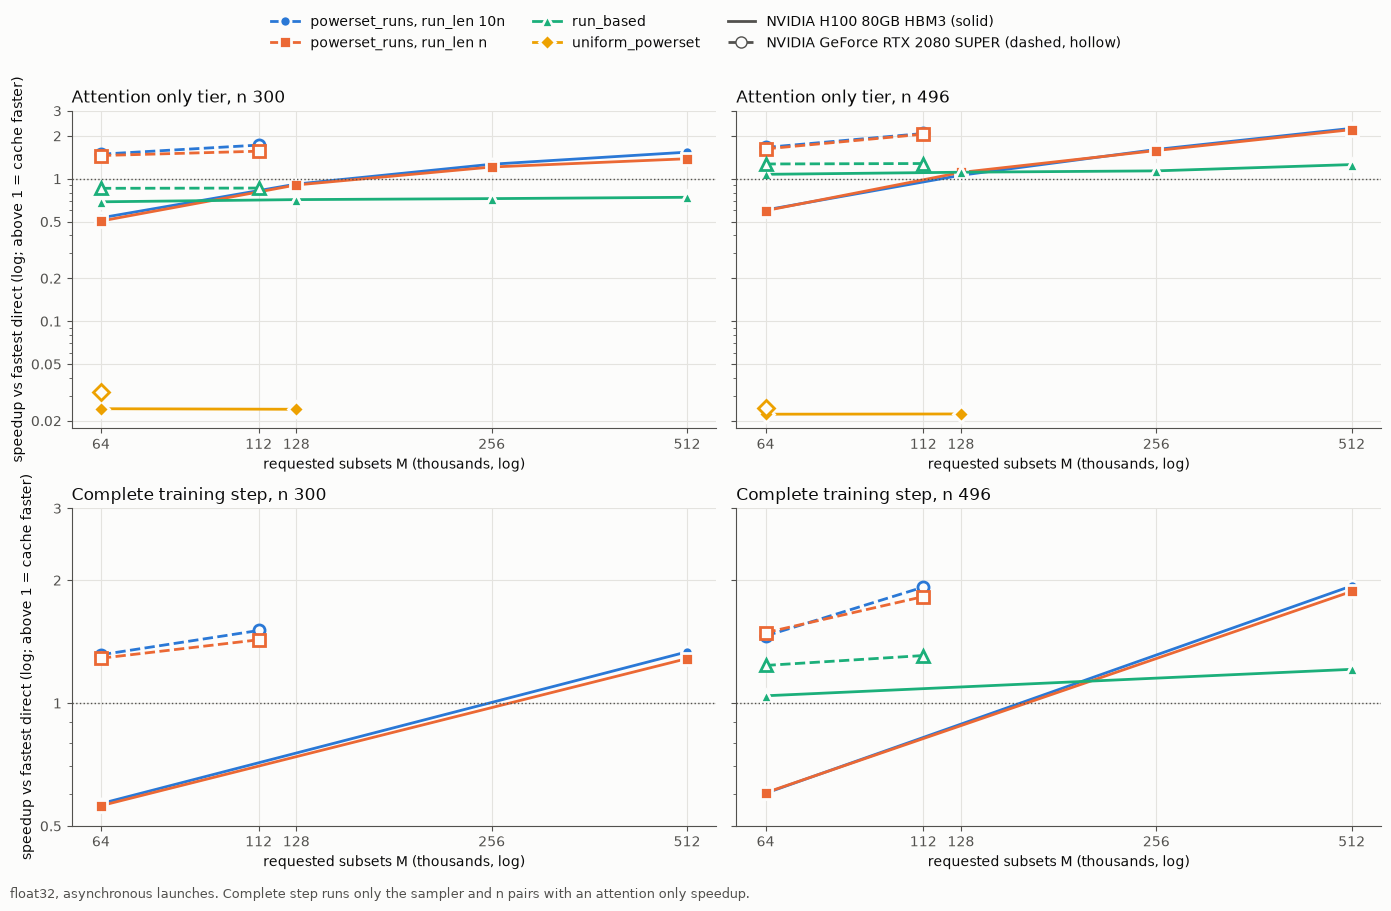

FIGURE 1 DATA (speedup_vs_best = fastest direct median / cache median):
          tier                           gpu          sampler run_len   n      M      P cache_status  cache_ms           best_direct  best_direct_ms  speedup_vs_best  direct_excluded
attention only NVIDIA GeForce RTX 2080 SUPER    powerset_runs     10n 300  64000  63000           ok   106.530 sdpa_masked_math@4096         158.588            1.489                0
attention only NVIDIA GeForce RTX 2080 SUPER    powerset_runs     10n 300 112000 111000           ok   161.554 sdpa_masked_math@4096         278.631            1.725                0
attention only NVIDIA GeForce RTX 2080 SUPER    powerset_runs       n 300  64000  63900           ok   117.370 sdpa_masked_math@1024         170.935            1.456                0
attention only NVIDIA GeForce RTX 2080 SUPER    powerset_runs       n 300 112000 111900           ok   181.256 sdpa_masked_math@4096         283.128            1.562                0
attention onl

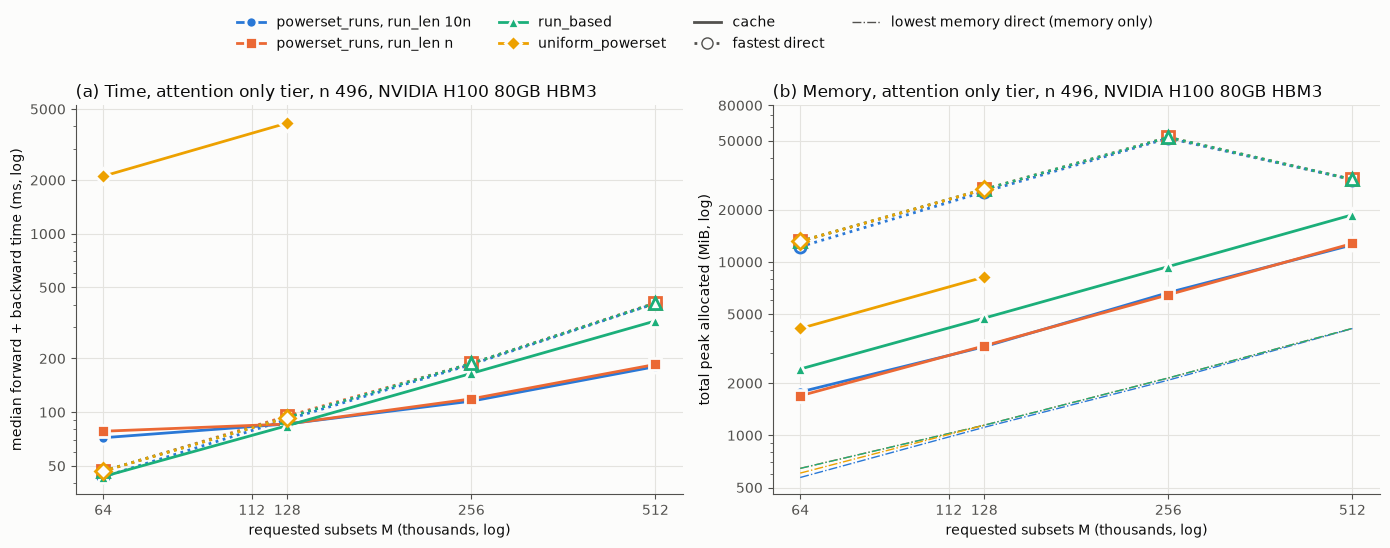

FIGURE 2 DATA (H100, attention only, n 496):
         sampler run_len      M      P cache_status  cache_ms          best_direct  best_direct_ms  cache_total_MiB  best_direct_total_MiB  lowest_direct_total_MiB
   powerset_runs     10n  64000  59520           ok      71.9 sdpa_masked_math@all            43.4           1778.8                12233.1                    571.2
   powerset_runs     10n 128000 124000           ok      85.9 sdpa_masked_math@all            91.0           3244.0                25392.5                   1112.4
   powerset_runs     10n 256000 252960           ok     115.3 sdpa_masked_math@all           185.2           6652.7                51712.6                   2080.6
   powerset_runs     10n 512000 510880           ok     180.1      sdpa_masked@all           407.1          12546.5                29831.7                   4129.1
   powerset_runs       n  64000  63984           ok      78.2 sdpa_masked_math@all            46.7           1689.6                1314

In [9]:
# H5. Figures and claims, H100 beside the RTX 2080 SUPER. Reads pvcb_results_h100.pkl.lz4 and
# pvcb_results_2080.pkl.lz4 only; no new measurement, nothing written. Every figure is followed by its data table.
# Figure 1: speedup_vs_best against requested M, rows = tier (attention only: H3 and V2C3a; complete step: H4 and
#           V2C4), columns = n (300, 496); H100 solid, RTX 2080 SUPER dashed; reference line at 1.
# Figure 2: H100 attention only, n 496, against M: (a) median time of the cache and of the fastest direct
#           configuration; (b) total peak memory of the cache, the fastest direct and the lowest memory direct.
# Same point comparison: H100 and 2080 at M 64,000, both tiers.
# Claims: C1, C2, C3, C6 on the H100, one block per claim, statuses computed from the data.

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter
PVCB_DIR = "/workspace/pvcb"
if PVCB_DIR not in sys.path:
    sys.path.insert(0, PVCB_DIR)
from apriori.serialization import load_from_pickle

RESULTS_H100 = os.path.join(PVCB_DIR, "pvcb_results_h100.pkl.lz4")
RESULTS_2080 = os.path.join(PVCB_DIR, "pvcb_results_2080.pkl.lz4")
sh = load_from_pickle(RESULTS_H100)
s8 = load_from_pickle(RESULTS_2080)
need_h = ("env", "equivalence", "h3_rows", "h3_points", "h4_rows", "h4_points", "h4_env")
need_8 = ("v2c3a_rows", "v2c4_rows", "env")
miss = [k for k in need_h if k not in sh] + [k for k in need_8 if k not in s8]
assert not miss, f"results files are missing {miss}"
assert sh["h4_env"]["launch_mode"] == "asynchronous"
GPU_H, GPU_8 = sh["env"]["gpu"], s8["env"]["gpu"]

# ----- style: fixed series colors and markers, text in ink colors -----
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = {("powerset_runs", "10n"): ("#2a78d6", "o", "powerset_runs, run_len 10n"),
          ("powerset_runs", "n"): ("#eb6834", "s", "powerset_runs, run_len n"),
          ("run_based", None): ("#1baf7a", "^", "run_based"),
          ("uniform_powerset", None): ("#eda100", "D", "uniform_powerset")}
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": INK2, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 2, "lines.markersize": 8, "font.size": 10})
M_TICKS = [64, 112, 128, 256, 512]

def series_handles():
    return [Line2D([], [], color=c, marker=m, lw=2, markeredgecolor=SURF, markeredgewidth=2, label=l)
            for c, m, l in SERIES.values()]

def rl_label(row):
    rl, n = row.get("run_len"), row["n"]
    if rl is None or (isinstance(rl, float) and np.isnan(rl)):
        return None
    return "n" if int(rl) == int(n) else ("10n" if int(rl) == 10 * int(n) else str(int(rl)))

def summarize(rows, keys):
    """Per point: cache median ms, fastest feasible direct median ms and configuration, speedup, memory."""
    g = pd.DataFrame(rows)
    out = []
    for key, sel in g.groupby(keys, dropna=False):
        c = sel[sel["impl"] == "cache"].iloc[0]
        d = sel[(sel["impl"] != "cache") & (sel["status"] == "ok")]
        best = d.loc[d["t_median_ms"].idxmin()] if len(d) else None
        low = d.loc[d["peak_alloc_MiB"].idxmin()] if len(d) else None
        ok = c["status"] == "ok" and best is not None
        out.append({**dict(zip(keys, key)), "P": int(c["P"]), "cache_status": c["status"],
                    "cache_ms": c["t_median_ms"],
                    "best_direct": "direct infeasible" if best is None else f"{best['impl']}@{best['chunk']}",
                    "best_direct_ms": np.nan if best is None else best["t_median_ms"],
                    "speedup_vs_best": best["t_median_ms"] / c["t_median_ms"] if ok else np.nan,
                    "cache_total_MiB": c["peak_alloc_MiB"],
                    "best_direct_total_MiB": np.nan if best is None else best["peak_alloc_MiB"],
                    "lowest_direct_total_MiB": np.nan if low is None else low["peak_alloc_MiB"],
                    "direct_excluded": int((sel["status"] == "excluded_slow").sum())})
    return pd.DataFrame(out)

def prep(rows, n_col, tier, gpu):
    g = pd.DataFrame(rows)
    g["rl"] = g["run_len_label"] if "run_len_label" in g else g.apply(rl_label, axis=1)
    if n_col != "n":
        g = g.drop(columns=["n"]).rename(columns={n_col: "n"})
    g["rl"] = g["rl"].fillna("none")
    s = summarize(g.to_dict("records"), ["sampler", "rl", "n", "M"])
    s["rl"] = s["rl"].replace("none", None)
    return s.assign(tier=tier, gpu=gpu)

h3 = prep(sh["h3_rows"], "n", "attention only", GPU_H)
h4 = prep(sh["h4_rows"], "n_target", "complete step", GPU_H)
a8 = prep(s8["v2c3a_rows"], "n", "attention only", GPU_8)
c8 = prep(s8["v2c4_rows"], "n_target", "complete step", GPU_8)
allp = pd.concat([h3, h4, a8, c8], ignore_index=True)

def log_ticks(ax, vals, cands):
    v = np.asarray([x for x in vals if np.isfinite(x) and x > 0])
    if not len(v):
        return
    t = [c for c in cands if v.min() / 1.6 <= c <= v.max() * 1.6]
    ax.set_yticks(t)
    ax.set_yticklabels([f"{c:g}" for c in t])
    ax.yaxis.set_minor_formatter(NullFormatter())

def m_axis(ax):
    ax.set_xscale("log", base=2)
    ax.set_xticks(M_TICKS)
    ax.set_xticklabels([str(m) for m in M_TICKS])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("requested subsets M (thousands, log)")

# ===== Figure 1: speedup against M, H100 and 2080 =====
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey="row")
for r, tier in enumerate(("attention only", "complete step")):
    for cidx, n in enumerate((300, 496)):
        ax = axes[r, cidx]
        sub = allp[(allp["tier"] == tier) & (allp["n"] == n)]
        for (smp, rl), (col, mk, lab) in SERIES.items():
            for gpu, ls, filled in ((GPU_H, "-", True), (GPU_8, "--", False)):
                sel = sub[(sub["gpu"] == gpu) & (sub["sampler"] == smp) & (sub["rl"].fillna("none") == (rl or "none"))
                          & sub["speedup_vs_best"].notna()].sort_values("M")
                if len(sel):
                    ax.plot(sel["M"] / 1000, sel["speedup_vs_best"], ls=ls, marker=mk, color=col,
                            markerfacecolor=col if filled else SURF, markeredgecolor=col if not filled else SURF,
                            markeredgewidth=2)
        ax.axhline(1.0, color=INK2, lw=1, ls=":")
        ax.set_yscale("log")
        log_ticks(ax, allp[allp["tier"] == tier]["speedup_vs_best"], [0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 3, 5, 10, 20])
        m_axis(ax)
        ax.set_title(f"{'Attention only tier' if tier == 'attention only' else 'Complete training step'}, n {n}",
                     color=INK, loc="left")
    axes[r, 0].set_ylabel("speedup vs fastest direct (log; above 1 = cache faster)")
handles = series_handles() + [Line2D([], [], color=INK2, ls="-", label=f"{GPU_H} (solid)"),
                              Line2D([], [], color=INK2, ls="--", marker="o", markerfacecolor=SURF,
                                     label=f"{GPU_8} (dashed, hollow)")]
fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.text(0.01, 0.005, "float32, asynchronous launches. Complete step runs only the sampler and n pairs with an attention "
         "only speedup.", color=INK2, fontsize=9)
plt.tight_layout(rect=(0, 0.02, 1, 0.92))
plt.show()
print("FIGURE 1 DATA (speedup_vs_best = fastest direct median / cache median):")
with pd.option_context("display.width", 260):
    print(allp.sort_values(["tier", "gpu", "n", "sampler", "rl", "M"], na_position="last")
          [["tier", "gpu", "sampler", "rl", "n", "M", "P", "cache_status", "cache_ms", "best_direct", "best_direct_ms",
            "speedup_vs_best", "direct_excluded"]].rename(columns={"rl": "run_len"}).round(3).to_string(index=False))

# ===== Figure 2: H100 attention only, n 496: time and memory against M =====
f2 = h3[h3["n"] == 496]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for (smp, rl), (col, mk, lab) in SERIES.items():
    sel = f2[(f2["sampler"] == smp) & (f2["rl"].fillna("none") == (rl or "none"))].sort_values("M")
    if not len(sel):
        continue
    axes[0].plot(sel["M"] / 1000, sel["cache_ms"], ls="-", marker=mk, color=col, markeredgecolor=SURF,
                 markeredgewidth=2)
    axes[0].plot(sel["M"] / 1000, sel["best_direct_ms"], ls=":", marker=mk, color=col, markerfacecolor=SURF,
                 markeredgecolor=col, markeredgewidth=2)
    axes[1].plot(sel["M"] / 1000, sel["cache_total_MiB"], ls="-", marker=mk, color=col, markeredgecolor=SURF,
                 markeredgewidth=2)
    axes[1].plot(sel["M"] / 1000, sel["best_direct_total_MiB"], ls=":", marker=mk, color=col, markerfacecolor=SURF,
                 markeredgecolor=col, markeredgewidth=2)
    axes[1].plot(sel["M"] / 1000, sel["lowest_direct_total_MiB"], ls="-.", color=col, lw=1)
for ax, ylab, title, vals, cands in (
        (axes[0], "median forward + backward time (ms, log)", "(a) Time", f2[["cache_ms", "best_direct_ms"]].values.ravel(),
         [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000]),
        (axes[1], "total peak allocated (MiB, log)", "(b) Memory",
         f2[["cache_total_MiB", "best_direct_total_MiB", "lowest_direct_total_MiB"]].values.ravel(),
         [100, 200, 500, 1000, 2000, 5000, 10000, 20000, 50000, 80000])):
    ax.set_yscale("log")
    log_ticks(ax, vals, cands)
    m_axis(ax)
    ax.set_ylabel(ylab)
    ax.set_title(f"{title}, attention only tier, n 496, {GPU_H}", color=INK, loc="left")
handles = series_handles() + [Line2D([], [], color=INK2, ls="-", label="cache"),
                              Line2D([], [], color=INK2, ls=":", marker="o", markerfacecolor=SURF,
                                     label="fastest direct"),
                              Line2D([], [], color=INK2, ls="-.", lw=1, label="lowest memory direct (memory only)")]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()
print("FIGURE 2 DATA (H100, attention only, n 496):")
with pd.option_context("display.width", 260):
    print(f2.sort_values(["sampler", "rl", "M"], na_position="last")
          [["sampler", "rl", "M", "P", "cache_status", "cache_ms", "best_direct", "best_direct_ms", "cache_total_MiB",
            "best_direct_total_MiB", "lowest_direct_total_MiB"]].rename(columns={"rl": "run_len"})
          .round(1).to_string(index=False))

# ===== same point comparison at M 64,000 =====
key = ["tier", "sampler", "rl", "n"]
p64 = allp[allp["M"] == 64000].copy()
p64["rl"] = p64["rl"].fillna("none")
cmp_ = (p64[p64["gpu"] == GPU_8][key + ["cache_ms", "best_direct_ms", "speedup_vs_best"]]
        .merge(p64[p64["gpu"] == GPU_H][key + ["cache_ms", "best_direct_ms", "speedup_vs_best"]],
               on=key, suffixes=("_2080", "_h100")))
cmp_["rl"] = cmp_["rl"].replace("none", None)
cmp_["cache_faster_x"] = cmp_["cache_ms_2080"] / cmp_["cache_ms_h100"]
cmp_["direct_faster_x"] = cmp_["best_direct_ms_2080"] / cmp_["best_direct_ms_h100"]
print(f"\nSAME POINT COMPARISON at M 64,000 ({GPU_8} vs {GPU_H}); cache_faster_x and direct_faster_x = 2080 time / "
      f"H100 time:")
with pd.option_context("display.width", 260):
    print(cmp_.sort_values(key, na_position="last").rename(columns={"rl": "run_len"}).round(3).to_string(index=False))

skipped = pd.DataFrame(list(sh.get("h3_skipped", [])) + list(sh.get("h4_skipped", [])))
if len(skipped):
    print("\nSKIPPED (growth rule or time guard), H3 then H4:")
    print(skipped.to_string(index=False))

# ===== claims =====
def frac_status(x):
    x = x.dropna()
    k, m = int((x > 1).sum()), len(x)
    if m == 0:
        return "not measured"
    return "supported" if k == m else ("not supported" if k == 0 else f"partly supported ({k} of {m} points)")

def rng(x, nd=2):
    x = x.dropna()
    return "none" if not len(x) else f"{x.min():.{nd}f}x to {x.max():.{nd}f}x"

eq = sh["equivalence"]
e64, e32 = eq[eq["dtype"] == "float64"], eq[eq["dtype"] == "float32"]
g4 = pd.DataFrame(sh["h4_rows"])
pr3 = h3[h3["sampler"] == "powerset_runs"]["speedup_vs_best"]
rb3_496 = h3[(h3["sampler"] == "run_based") & (h3["n"] == 496)]["speedup_vs_best"]
rb3_300 = h3[(h3["sampler"] == "run_based") & (h3["n"] == 300)]["speedup_vs_best"]
up3 = h3[h3["sampler"] == "uniform_powerset"]
pr4 = h4[h4["sampler"] == "powerset_runs"]["speedup_vs_best"]
rb4 = h4[h4["sampler"] == "run_based"]["speedup_vs_best"]
infeas = h3[(h3["cache_status"] == "ok") & (h3["best_direct"] == "direct infeasible")]
mem = h3[(h3["cache_status"] == "ok") & h3["best_direct_total_MiB"].notna()]
above_fast = int((mem["cache_total_MiB"] > mem["best_direct_total_MiB"]).sum())
above_low = int((mem["cache_total_MiB"] > mem["lowest_direct_total_MiB"]).sum())
c2_status = ("supported" if above_fast == 0 and above_low == 0 else
             ("not supported" if above_low == len(mem) else "partly supported"))
c6_rows = []
for (smp, rl, n), sel in h3[h3["speedup_vs_best"].notna()].groupby(["sampler", h3["rl"].fillna("none"), "n"]):
    sel = sel.sort_values("M")
    if len(sel) >= 2:
        sp = sel["speedup_vs_best"].to_numpy()
        c6_rows.append({"sampler": smp, "rl": rl, "n": n, "M_first": int(sel["M"].iloc[0]),
                        "M_last": int(sel["M"].iloc[-1]), "first": sp[0], "last": sp[-1],
                        "rises_every_step": bool(np.all(np.diff(sp) > 0))})
c6 = pd.DataFrame(c6_rows)
c6_pr = c6[c6["sampler"] == "powerset_runs"] if len(c6) else c6
c6_status = ("not measured" if not len(c6_pr) else
             "supported" if bool((c6_pr["last"] > c6_pr["first"]).all()) else
             "not supported" if bool((c6_pr["last"] <= c6_pr["first"]).all()) else "partly supported")
c6_txt = "; ".join(f"{r.sampler} {'' if r.rl == 'none' else 'L ' + r.rl + ' '}n {r.n}: {r.first:.2f}x at "
                   f"{r.M_first // 1000}k to {r.last:.2f}x at {r.M_last // 1000}k"
                   f"{'' if r.rises_every_step else ' (not rising at every step)'}" for r in c6.itertuples())
claims = [
    ("C1 exactness", "supported" if (eq["status"] == "ok").all() and len(g4) else "not supported",
     f"H1: {int((eq['status'] == 'ok').sum())} of {len(eq)} comparisons within tolerance, "
     f"{int((eq['status'] == 'FAIL').sum())} failures; largest float64 error "
     f"{np.nanmax(e64[['err_out', 'err_grad_q', 'err_grad_K', 'err_grad_V']].to_numpy()):.1e}; largest float32 "
     f"gradient relative difference {np.nanmax(e32[['err_grad_q', 'err_grad_K', 'err_grad_V']].to_numpy()):.1e}; "
     f"H4 complete step gradients within {g4['grad_rel_all'].max():.1e} of the reference"),
    ("C2 memory", c2_status,
     f"H3 points with the cache and a direct configuration feasible: cache total peak above the fastest direct "
     f"configuration at {above_fast} of {len(mem)} and above the lowest memory direct configuration at "
     f"{above_low} of {len(mem)}; direct infeasible (cache fits, every direct configuration out of memory) at "
     f"{len(infeas)} points"),
    ("C3 time, attention only", f"powerset_runs: {frac_status(pr3)}",
     f"powerset_runs {rng(pr3)} ({pr3.notna().sum()} points); run_based n 496 {rng(rb3_496)}; run_based n 300 "
     f"{rng(rb3_300, 3)}; uniform_powerset {rng(up3['speedup_vs_best'])} with the cache out of memory at "
     f"{int((up3['cache_status'] == 'oom').sum())} of {len(up3)} points"),
    ("C3 time, complete step", f"powerset_runs: {frac_status(pr4)}; run_based: {frac_status(rb4)}",
     f"powerset_runs {rng(pr4)} ({pr4.notna().sum()} points); run_based {rng(rb4)} ({rb4.notna().sum()} points)"),
    ("C6 scaling with M (attention only)", f"powerset_runs: {c6_status}", c6_txt or "fewer than two measured M"),
]
print(f"\nH5 CLAIMS ({GPU_H}, float32, asynchronous launches):")
for claim, status, evidence in claims:
    print(f"\n{claim}\n  status: {status}\n  evidence: {evidence}")

## H5 findings

**Figure 1 and FIGURE 1 DATA (speedup against M, H100 beside the 2080)**

- **Attention only:** the H100 lines for `powerset_runs` start below parity at M 64,000 (0.51x to 0.60x) and rise at every doubling, to 1.38x to 2.26x at 512,000. The 2080 lines sit above parity at 64,000 and 112,000 (1.46x to 2.08x), but stop at 112,000, where the 8 GB card ran out of memory.
- **Complete step:** the same shape. On the H100, 0.56x to 0.60x at M 64,000 and 1.29x to 1.94x at 512,000; on the 2080, 1.29x to 1.92x at 64,000 and 112,000.
- **Negative controls:** `uniform_powerset` stays at 0.02x to 0.03x on both GPUs. `run_based` at n 300 stays below parity on both (H100 0.69x to 0.74x).

**Figure 2 and FIGURE 2 DATA (H100, attention only, n 496)**

- **(a) Time:** direct time doubles with every doubling of M (about 45, 93, 187 and 408 ms). The cache on `powerset_runs` starts higher (72 to 78 ms) and grows more slowly (180 to 185 ms at 512,000), so the lines cross between 64,000 and 128,000.
- **(b) Memory:** the cache (1.7 to 12.8 GB) stays below the fastest direct configuration (12.2 to 52.3 GB), and above the lowest memory direct configuration (0.6 to 4.1 GB).

**SAME POINT COMPARISON (M 64,000, H100 against 2080)**

| Configuration | H100 speedup over the 2080 |
|---|---|
| Fastest direct configuration | 4.6x to 6.2x |
| Cache, `powerset_runs` (deep tries, 174 to 280 levels) | 1.8x to 2.1x |
| Cache, `run_based` (shallow tries, 64 levels) | 3.9x to 4.3x |
| Cache, `uniform_powerset` | 4.5x to 4.7x |

- The H100 sped up standard attention more than the cache at this size, which is why the 2080's speedups at M 64,000 become slowdowns here.
- The cache gained least on the deepest tries, consistent with a cost paid per trie level that faster hardware does not shrink as much.
- In plain terms: a faster GPU raises the number of subsets the cache needs before it wins, but past that point the cache's lead is larger than before.

**SKIPPED**: none. All 28 H3 points and all 10 H4 points were measured within the time guards.

**H5 CLAIMS (H100)**

| Claim | Status | Evidence |
|---|---|---|
| C1 exactness | Supported | H1: 1,024 of 1,024 comparisons, largest float64 error 4.1e-13, largest float32 gradient difference 1.1e-6; H4: complete step gradients within 2.4e-6 of the reference |
| C2 memory | Not supported | Above the lowest memory direct configuration at 28 of 28 H3 points. Below the fastest direct configuration at 26 of 28 (above only for `uniform_powerset` at n 300); no point was direct infeasible |
| C3 time, attention only | Partly supported (`powerset_runs` faster at 10 of 16 points) | `powerset_runs` 0.51x to 2.26x, faster at every point from M 128,000 (n 496) or 256,000 (n 300); `run_based` n 496 1.07x to 1.26x; `run_based` n 300 0.689x to 0.741x; `uniform_powerset` 0.02x |
| C3 time, complete step | `powerset_runs` partly supported (4 of 8 points); `run_based` supported | `powerset_runs` 0.56x to 1.94x, faster at every M 512,000 point and slower at every M 64,000 point; `run_based` 1.04x and 1.21x |
| C6 scaling with M | Supported | `powerset_runs` at n 496: 0.60x to 2.26x (L 10n) and 0.60x to 2.21x (L n); at n 300: 0.53x to 1.54x and 0.51x to 1.38x, rising at every doubling. `run_based`: 0.69x to 0.74x (n 300) and 1.07x to 1.26x (n 496). `uniform_powerset` flat at about 0.02x (marked not rising at every step only because 0.0243x to 0.0241x is a rounding level decrease) |

**Conclusion across both GPUs**: exactness holds on both. On both GPUs, the cache's training advantage grows with the number of subsets it reuses across. A faster GPU raises the crossover point (from below M 64,000 on the RTX 2080 SUPER to about 128,000 to 256,000 on the H100), and lifts the advantage reached past it (2.26x attention only and 1.94x complete step at M 512,000). The cache is not leaner than the leanest standard configuration on either GPU.